In [5]:
import sys
import tensorflow as tf
import pandas as pd
import numpy as np

print("Python executable:", sys.executable)
print("TensorFlow:", tf.__version__)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Notebook environment is ready!")

Python executable: c:\Users\patel\OneDrive\Desktop\R&W\Deep Learning\PR 5\.venv\Scripts\python.exe
TensorFlow: 2.21.0
Pandas: 3.0.6
NumPy: 2.4.6
Notebook environment is ready!


In [6]:

import pandas as pd

# Load the dataset
df = pd.read_csv("IMDB Dataset.csv")

# 1. Dataset shape
print("Dataset Shape:", df.shape)

# 2. First five rows
print("\nFirst Five Rows:")
display(df.head())

# 3. Sentiment distribution
print("\nSentiment Distribution:")
print(df["sentiment"].value_counts())

# 4. Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 5. First raw review in full
print("\nFirst Raw Review:")
print(df["review"].iloc[0])

# 6. Second raw review in full
print("\nSecond Raw Review:")
print(df["review"].iloc[1])


Dataset Shape: (50000, 2)

First Five Rows:


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive



Sentiment Distribution:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64

Missing Values:
review       0
sentiment    0
dtype: int64

First Raw Review:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Ita

In [7]:

# Task 1.2: Remove Duplicate Reviews

# Record the number of rows before removal
rows_before = len(df)

# Count exact duplicate rows
duplicate_count = df.duplicated().sum()

print("Rows before removing duplicates:", rows_before)
print("Number of duplicate rows:", duplicate_count)

# Remove exact duplicate rows
df.drop_duplicates(inplace=True)

# Record rows after removal
rows_after = len(df)

print("\nRows after removing duplicates:", rows_after)
print("Rows removed:", rows_before - rows_after)

# Verify that no exact duplicates remain
print("Remaining duplicate rows:", df.duplicated().sum())


Rows before removing duplicates: 50000
Number of duplicate rows: 418

Rows after removing duplicates: 49582
Rows removed: 418
Remaining duplicate rows: 0


In [8]:
# Task 1.3: Text Cleaning

import re

def clean_text(s):
    # Convert text to lowercase
    s = str(s).lower()

    # Remove HTML tags
    s = re.sub(r'<.*?>', ' ', s)

    # Keep only English letters and apostrophes
    s = re.sub(r"[^a-z']", ' ', s)

    # Normalise whitespace
    s = re.sub(r'\s+', ' ', s).strip()

    return s


# Apply text cleaning while preserving the original reviews
df["clean_review"] = df["review"].apply(clean_text)

print("Text cleaning completed successfully.")
print("Dataset shape:", df.shape)
print("Original review column:", "review")
print("Cleaned review column:", "clean_review")

Text cleaning completed successfully.
Dataset shape: (49582, 3)
Original review column: review
Cleaned review column: clean_review


In [9]:
# Display one review before and after cleaning

sample_index = 0

print("BEFORE CLEANING:\n")
print(df["review"].iloc[sample_index])

print("\n" + "=" * 70 + "\n")

print("AFTER CLEANING:\n")
print(df["clean_review"].iloc[sample_index])


BEFORE CLEANING:

One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the show

In [10]:
# Verify the cleaned reviews

print("Missing values in cleaned reviews:",
      df["clean_review"].isnull().sum())

print("\nOriginal review:")
print(df["review"].iloc[0][:200])

print("\nCleaned review:")
print(df["clean_review"].iloc[0][:200])

Missing values in cleaned reviews: 0

Original review:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me abo

Cleaned review:
one of the other reviewers has mentioned that after watching just oz episode you'll be hooked they are right as this is exactly what happened with me the first thing that struck me about oz was its br


In [11]:
# Task 1.4: Calculate word counts

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Count words in each cleaned review
df["word_count"] = df["clean_review"].apply(
    lambda text: len(text.split())
)

# Calculate statistics
mean_words = df["word_count"].mean()
median_words = df["word_count"].median()
percentile_95 = np.percentile(df["word_count"], 95)

print("Word Count Statistics")
print("-" * 35)
print(f"Mean word count: {mean_words:.2f}")
print(f"Median word count: {median_words:.2f}")
print(f"95th percentile: {percentile_95:.2f}")
print(f"Minimum word count: {df['word_count'].min()}")
print(f"Maximum word count: {df['word_count'].max()}")

Word Count Statistics
-----------------------------------
Mean word count: 229.96
Median word count: 172.00
95th percentile: 587.00
Minimum word count: 6
Maximum word count: 2462


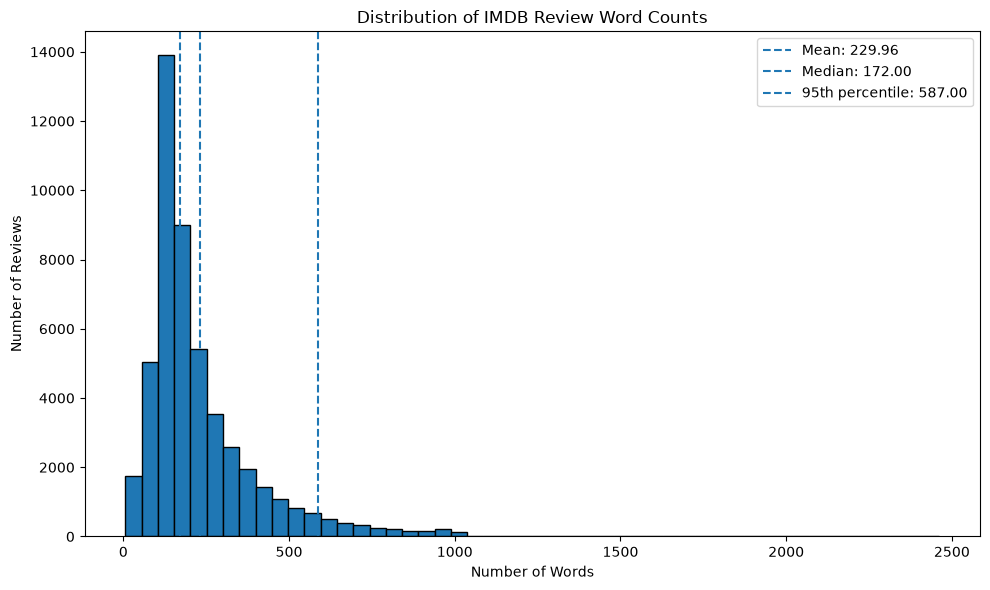

In [12]:
# Histogram of review word counts

plt.figure(figsize=(10, 6))

plt.hist(df["word_count"], bins=50, edgecolor="black")

plt.axvline(mean_words, linestyle="--",
            label=f"Mean: {mean_words:.2f}")
plt.axvline(median_words, linestyle="--",
            label=f"Median: {median_words:.2f}")
plt.axvline(percentile_95, linestyle="--",
            label=f"95th percentile: {percentile_95:.2f}")

plt.title("Distribution of IMDB Review Word Counts")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")
plt.legend()
plt.tight_layout()
plt.savefig("histogram.png")
plt.show()

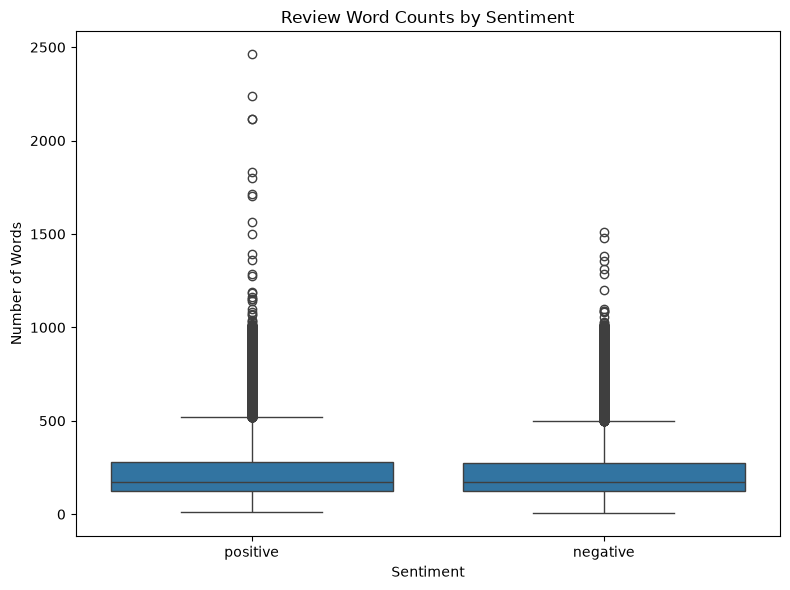

In [13]:
# Compare review lengths by sentiment

plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x="sentiment",
    y="word_count"
)

plt.title("Review Word Counts by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of Words")
plt.tight_layout()
plt.savefig("boxplot.png")
plt.show()

In [14]:
# Select a practical maximum sequence length

percentile_90 = np.percentile(df["word_count"], 90)

# Round the 95th percentile up to the nearest 10 words
MAXLEN = int(np.ceil(percentile_95 / 10) * 10)

print(f"90th percentile: {percentile_90:.2f}")
print(f"95th percentile: {percentile_95:.2f}")
print(f"Selected MAXLEN: {MAXLEN}")

90th percentile: 449.00
95th percentile: 587.00
Selected MAXLEN: 590


In [15]:
# Prepare data for tokenization

from sklearn.model_selection import train_test_split

X = df["clean_review"]
y = df["sentiment"].map({"positive": 1, "negative": 0})

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))

Training reviews: 39665
Testing reviews: 9917


In [16]:
# Task 1.5: Tokenization

from tensorflow.keras.preprocessing.text import Tokenizer

tokenizer = Tokenizer(
    num_words=10000,
    oov_token="<OOV>"
)

# Fit only on training reviews
tokenizer.fit_on_texts(X_train)

# Convert training and testing reviews to integer sequences
X_train_sequences = tokenizer.texts_to_sequences(X_train)
X_test_sequences = tokenizer.texts_to_sequences(X_test)

print("Tokenizer created successfully.")
print("Vocabulary size:", len(tokenizer.word_index))
print("Training sequences:", len(X_train_sequences))
print("Testing sequences:", len(X_test_sequences))

Tokenizer created successfully.
Vocabulary size: 108132
Training sequences: 39665
Testing sequences: 9917


In [17]:
# Display the 10 most frequent words

most_frequent_words = sorted(
    tokenizer.word_counts.items(),
    key=lambda item: item[1],
    reverse=True
)[:10]

print("Top 10 most frequent words:")
for word, count in most_frequent_words:
    print(f"{word}: {count}")

Top 10 most frequent words:
the: 529753
and: 258038
a: 256817
of: 230096
to: 212541
is: 167548
in: 148539
it: 124849
i: 122942
this: 119750


In [18]:
# Display one cleaned review and its integer sequence

sample_position = 0

print("Cleaned review:")
print(X_train.iloc[sample_position])

print("\nInteger sequence:")
print(X_train_sequences[sample_position])

Cleaned review:
i am one of jehovah's witnesses and i also work in an acute care medical facility over the years i have seen people die from hemolytic reactions to blood transfusions have attended numerous conferences on blood born pathogens and have seen several patients become seriously ill from pathogens induced by transfused blood i have also heard several jehovah's witnesses being told that they will die if they refuse blood and after years in the field i have never actually seen it happen leaving the question is it really unreasonable to refuse blood transfusions or is the community at large benefiting from the battle on this issue the issue for jehovah's witnesses is a moral one you must abstain from blood is not an ambiguous statement thank you for this movie and allowing comments on it

Integer sequence:
[10, 234, 27, 5, 1, 4935, 3, 10, 81, 158, 8, 32, 1, 454, 2767, 7929, 121, 2, 151, 10, 25, 105, 83, 705, 35, 1, 3781, 6, 547, 1, 25, 6453, 1909, 1, 20, 547, 1417, 1, 3, 25, 105

In [19]:
# Task 1.6: Padding Sequences

import numpy as np
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Verify MAXLEN from Task 1.4
print("Selected MAXLEN:", MAXLEN)

# Pad and truncate training sequences
X_train_padded = pad_sequences(
    X_train_sequences,
    maxlen=MAXLEN,
    padding="pre",
    truncating="pre"
)

# Pad and truncate testing sequences
X_test_padded = pad_sequences(
    X_test_sequences,
    maxlen=MAXLEN,
    padding="pre",
    truncating="pre"
)

# Convert labels to NumPy arrays
y_train_array = np.asarray(y_train, dtype=np.int32)
y_test_array = np.asarray(y_test, dtype=np.int32)

print("\nPadding completed successfully.")
print("X_train_padded shape:", X_train_padded.shape)
print("X_test_padded shape:", X_test_padded.shape)
print("y_train_array shape:", y_train_array.shape)
print("y_test_array shape:", y_test_array.shape)

Selected MAXLEN: 590

Padding completed successfully.
X_train_padded shape: (39665, 590)
X_test_padded shape: (9917, 590)
y_train_array shape: (39665,)
y_test_array shape: (9917,)


In [20]:
# Verify that every padded sequence has the same length

print("Expected sequence length:", MAXLEN)
print("Training sequence lengths:", np.unique(
    [len(seq) for seq in X_train_padded]
))
print("Testing sequence lengths:", np.unique(
    [len(seq) for seq in X_test_padded]
))

print("\nExample padded training sequence:")
print(X_train_padded[0])

print("\nNumber of padding zeros in example:",
      np.sum(X_train_padded[0] == 0))

Expected sequence length: 590
Training sequence lengths: [590]
Testing sequence lengths: [590]

Example padded training sequence:
[   0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0   

In [21]:
# Task 1: Final preprocessing checkpoint

print("Original dataset shape:", df.shape)
print("Cleaned reviews available:", "clean_review" in df.columns)
print("Word counts available:", "word_count" in df.columns)
print("Tokenizer available:", "tokenizer" in globals())
print("MAXLEN:", MAXLEN)
print("Training input shape:", X_train_padded.shape)
print("Testing input shape:", X_test_padded.shape)
print("Training labels shape:", y_train_array.shape)
print("Testing labels shape:", y_test_array.shape)

assert len(X_train_padded) == len(y_train_array)
assert len(X_test_padded) == len(y_test_array)
assert X_train_padded.shape[1] == MAXLEN
assert X_test_padded.shape[1] == MAXLEN

print("\nTask 1 preprocessing checkpoint passed!")

Original dataset shape: (49582, 4)
Cleaned reviews available: True
Word counts available: True
Tokenizer available: True
MAXLEN: 590
Training input shape: (39665, 590)
Testing input shape: (9917, 590)
Training labels shape: (39665,)
Testing labels shape: (9917,)

Task 1 preprocessing checkpoint passed!


### Task 1.7: Sentiment Analysis as a Sequential Learning Problem

Sentiment analysis is a sequential learning problem because the meaning of a review depends not only on individual words but also on their order and context.

For example, the sentences "The movie was good" and "The movie was not good" contain similar words, but their sentiments are different. The word "not" changes the meaning of the sentence.

Recurrent neural network architectures such as SimpleRNN, LSTM, and GRU process text as a sequence of tokens and learn patterns from word order and context.

- **SimpleRNN:** Processes sequential information using a recurrent hidden state.
- **LSTM:** Uses memory cells and gates to learn longer-term dependencies.
- **GRU:** Uses update and reset gates to control information flow through the sequence.

Therefore, preserving word order and important words during preprocessing is essential for accurate sentiment classification.

# Task 2

In [22]:
# Task 2.1: Build the ANN baseline

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Flatten, Dense

# Reproducibility
tf.random.set_seed(42)

ann_model = Sequential([
    Embedding(
        input_dim=10000,
        output_dim=32,
        input_length=MAXLEN
    ),
    Flatten(),
    Dense(64, activation="relu"),
    Dense(1, activation="sigmoid")
])

ann_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

ann_model.build(input_shape=(None, MAXLEN))

ann_model.summary()

c:\Users\patel\OneDrive\Desktop\R&W\Deep Learning\PR 5\.venv\Lib\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 590, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 18880)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,208,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,528,449 (5.83 MB)

 Trainable params: 1,528,449 (5.83 MB)

 Non-trainable params: 0 (0.00 B)

In [23]:
# Train the ANN baseline

import time

ann_start_time = time.time()

ann_history = ann_model.fit(
    X_train_padded,
    y_train_array,
    epochs=5,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

ann_training_time = time.time() - ann_start_time

print(f"\nTotal ANN training time: {ann_training_time:.2f} seconds")

Epoch 1/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.7816 - loss: 0.4239 - val_accuracy: 0.8924 - val_loss: 0.2693
Epoch 2/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.9356 - loss: 0.1678 - val_accuracy: 0.8795 - val_loss: 0.3126
Epoch 3/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9847 - loss: 0.0529 - val_accuracy: 0.8724 - val_loss: 0.4446
Epoch 4/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.9973 - loss: 0.0136 - val_accuracy: 0.8727 - val_loss: 0.5146
Epoch 5/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.9993 - loss: 0.0043 - val_accuracy: 0.8714 - val_loss: 0.5907

Total ANN training time: 24.10 seconds


In [24]:
# Evaluate ANN on unseen test data

ann_test_loss, ann_test_accuracy = ann_model.evaluate(
    X_test_padded,
    y_test_array,
    verbose=0
)

ann_parameter_count = ann_model.count_params()

print(f"ANN test loss: {ann_test_loss:.4f}")
print(f"ANN test accuracy: {ann_test_accuracy:.4f}")
print(f"ANN test accuracy (%): {ann_test_accuracy * 100:.2f}%")
print(f"ANN trainable and non-trainable parameters: {ann_parameter_count:,}")

ANN test loss: 0.6091
ANN test accuracy: 0.8754
ANN test accuracy (%): 87.54%
ANN trainable and non-trainable parameters: 1,528,449


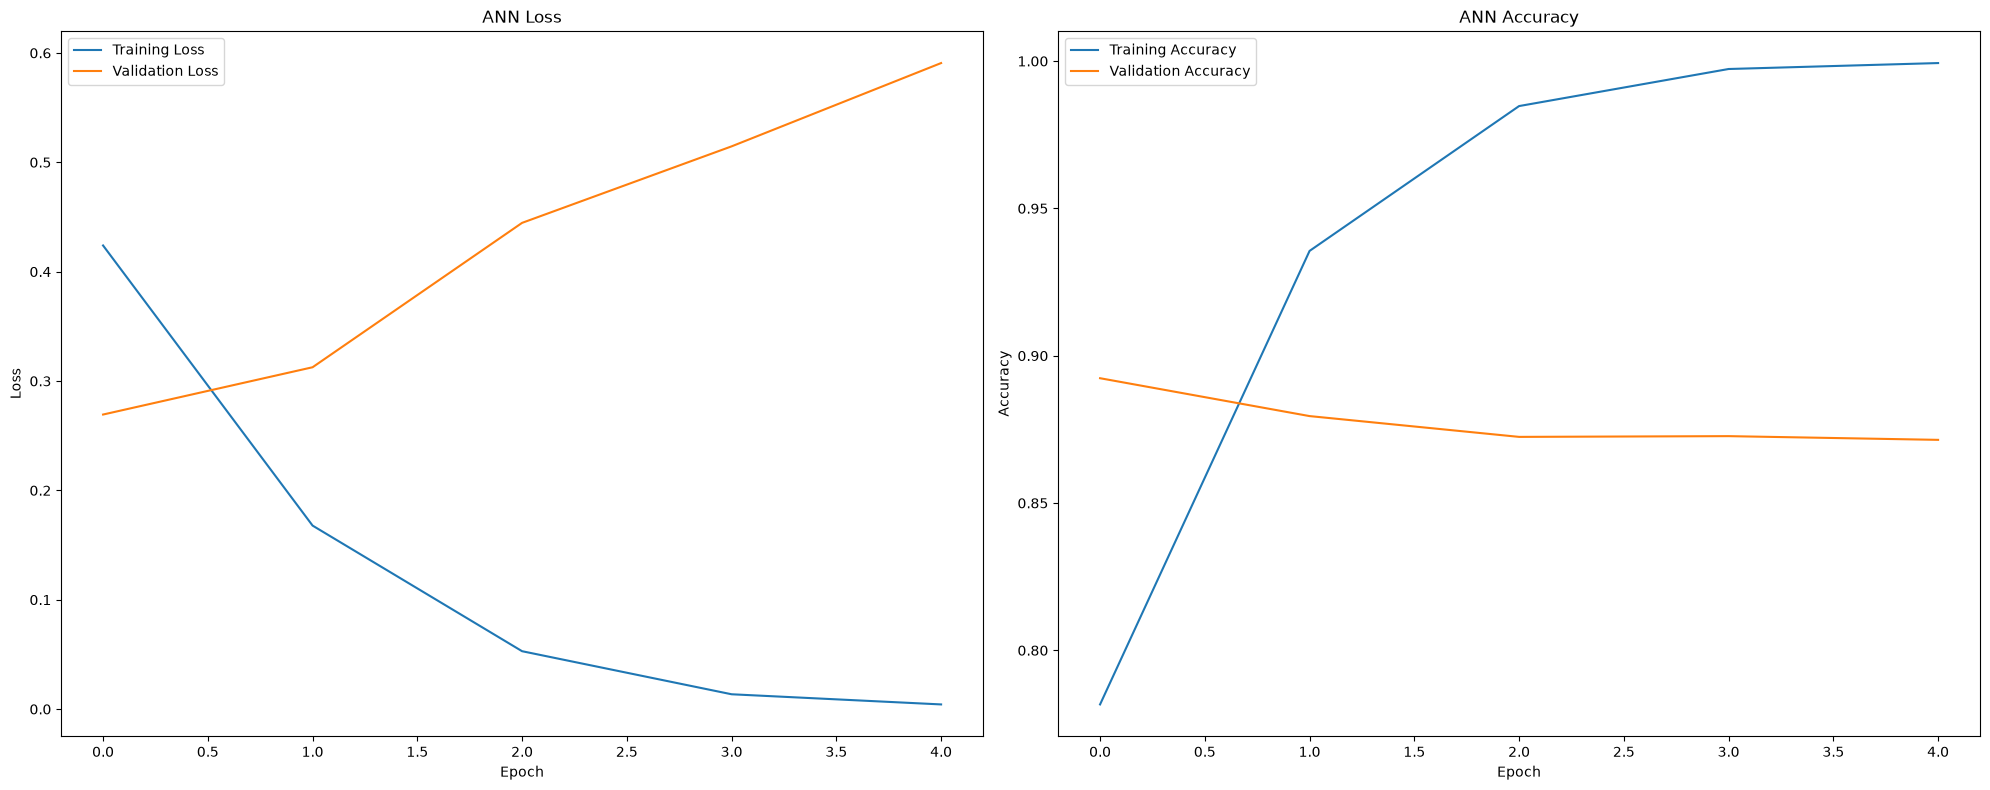

In [25]:
# Plot ANN training and validation curves

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

axes[0].plot(ann_history.history["loss"], label="Training Loss")
axes[0].plot(ann_history.history["val_loss"], label="Validation Loss")
axes[0].set_title("ANN Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(ann_history.history["accuracy"], label="Training Accuracy")
axes[1].plot(ann_history.history["val_accuracy"], label="Validation Accuracy")
axes[1].set_title("ANN Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.savefig("loss_&_acc")
plt.show()

### Task 2.2: RNN Intuition 

**Objective:** Understand how a Recurrent Neural Network processes sequential data using a hidden state and shared weights.

A Recurrent Neural Network (RNN) is a neural network designed to process sequential data, such as movie reviews, speech, and time-series data.

Unlike a basic Artificial Neural Network (ANN), an RNN processes one input at a time and maintains a hidden state that carries information from previous time steps.

For sentiment analysis, the input is a sequence of word embeddings. At each time step, the RNN receives the current word embedding and the previous hidden state. It combines this information to calculate a new hidden state.

**Hidden-state equation:**

h(t) = tanh(Wxh · x(t) + Whh · h(t−1) + b)

Where:

- `h(t)` is the current hidden state.
- `x(t)` is the current input word embedding.
- `h(t−1)` is the previous hidden state.
- `Wxh` is the input-to-hidden weight matrix.
- `Whh` is the hidden-to-hidden recurrent weight matrix.
- `b` is the bias vector.
- `tanh` is the activation function that introduces non-linearity.

The initial hidden state is commonly set to a vector of zeros.

**Output equation:**

y(t) = f(Why · h(t) + by)

Here, `Why` is the hidden-to-output weight matrix, `by` is the output bias, and `f` is the output activation function. For binary sentiment classification, a sigmoid activation can produce a probability between 0 and 1.

**Weight sharing across time:**

The same input weights, recurrent weights, and biases are reused at every time step. This is called weight sharing. It allows an RNN to process sequences of different lengths without creating a separate set of parameters for every word position.

**Why RNNs are useful:**

RNNs maintain information from earlier words while processing later words. This helps them learn word order and context, which are important for sentiment classification. For example, "not good" and "good" can express different sentiments even though they share the word "good".

In [26]:
# Task 2.3: Initialise the RNN

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set random seed
np.random.seed(42)

# Dimensions
input_size = 2
hidden_size = 3
time_steps = 4

# Initialise weights and bias
Wxh = np.random.randn(hidden_size, input_size) * 0.5
Whh = np.random.randn(hidden_size, hidden_size) * 0.5
b = np.random.randn(hidden_size) * 0.5

# Four-step input sequence: shape (4, 2)
X_manual = np.random.randn(time_steps, input_size)

# Initial hidden state
h_prev = np.zeros(hidden_size)

print("Wxh shape:", Wxh.shape)
print("Whh shape:", Whh.shape)
print("Bias shape:", b.shape)
print("Input sequence shape:", X_manual.shape)
print("\nInput sequence:\n", X_manual)

Wxh shape: (3, 2)
Whh shape: (3, 3)
Bias shape: (3,)
Input sequence shape: (4, 2)

Input sequence:
 [[-0.90802408 -1.4123037 ]
 [ 1.46564877 -0.2257763 ]
 [ 0.0675282  -1.42474819]
 [-0.54438272  0.11092259]]


In [27]:
# Manually calculate hidden states across four time steps

hidden_states = []

for t in range(time_steps):
    x_t = X_manual[t]

    # RNN hidden-state equation
    h_t = np.tanh(Wxh @ x_t + Whh @ h_prev + b)

    hidden_states.append(h_t)

    print(f"Hidden state h({t + 1}):")
    print(h_t)
    print()

    # Carry current state to the next time step
    h_prev = h_t

# Convert hidden states to a NumPy array
hidden_states = np.array(hidden_states)

print("Hidden states array shape:", hidden_states.shape)

Hidden state h(1):
[-0.38764228 -0.95413177  0.4042915 ]

Hidden state h(2):
[-0.58408135 -0.17994878  0.48472356]

Hidden state h(3):
[-6.69536884e-01 -9.46717183e-01 -5.59973976e-04]

Hidden state h(4):
[-0.86574174 -0.50825963  0.7751175 ]

Hidden states array shape: (4, 3)


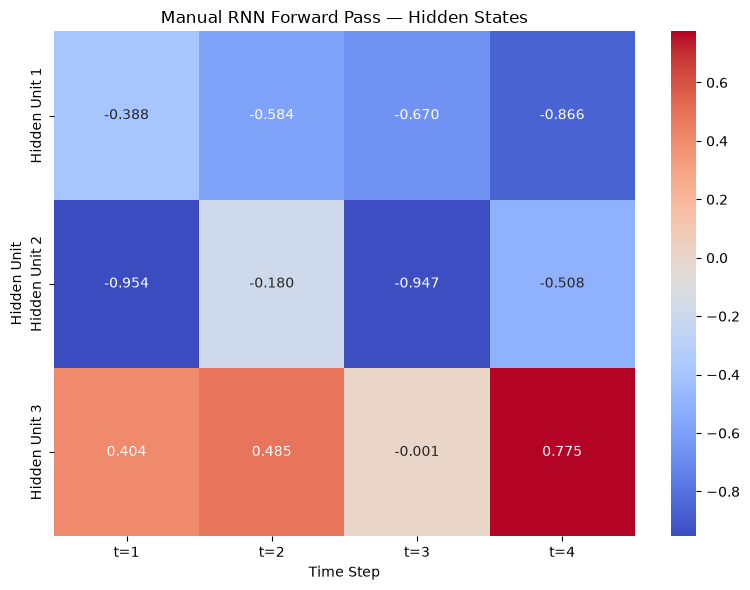

In [28]:
# Visualise hidden states using a heatmap

plt.figure(figsize=(8, 6))

sns.heatmap(
    hidden_states.T,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    xticklabels=[f"t={t}" for t in range(1, time_steps + 1)],
    yticklabels=[f"Hidden Unit {i}" for i in range(1, hidden_size + 1)]
)

plt.title("Manual RNN Forward Pass — Hidden States")
plt.xlabel("Time Step")
plt.ylabel("Hidden Unit")
plt.tight_layout()
plt.savefig("heatmap.png")
plt.show()

In [29]:
# Task 2.4: Verify manual RNN against Keras

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, SimpleRNN

# Build a Keras SimpleRNN with the required configuration
manual_keras_rnn = Sequential([
    Input(shape=(time_steps, input_size)),
    SimpleRNN(
        units=hidden_size,
        return_sequences=True,
        use_bias=True,
        activation="tanh"
    )
])

# Build the model before setting weights
_ = manual_keras_rnn(
    np.zeros((1, time_steps, input_size), dtype=np.float32)
)

# Copy the NumPy weights into Keras
manual_keras_rnn.layers[0].set_weights([
    Wxh.T.astype(np.float32),
    Whh.T.astype(np.float32),
    b.astype(np.float32)
])

print("Keras RNN created and NumPy weights copied successfully.")
print("Input kernel shape:", manual_keras_rnn.layers[0].get_weights()[0].shape)
print("Recurrent kernel shape:", manual_keras_rnn.layers[0].get_weights()[1].shape)
print("Bias shape:", manual_keras_rnn.layers[0].get_weights()[2].shape)

Keras RNN created and NumPy weights copied successfully.
Input kernel shape: (2, 3)
Recurrent kernel shape: (3, 3)
Bias shape: (3,)


In [30]:

# Run the same sequence through Keras

X_manual_batch = X_manual[np.newaxis, :, :].astype(np.float32)

keras_hidden_states = manual_keras_rnn(
    X_manual_batch,
    training=False
).numpy()[0]

print("Manual NumPy hidden states:")
print(hidden_states)

print("\nKeras hidden states:")
print(keras_hidden_states)

# Compare outputs within numerical tolerance
match = np.allclose(
    hidden_states,
    keras_hidden_states,
    rtol=1e-5,
    atol=1e-6
)

print("\nDo the NumPy and Keras outputs match?", match)

if match:
    print("SUCCESS: Manual RNN forward pass matches Keras SimpleRNN.")
else:
    print("Check the weights, input sequence, activation and initial state.")

Manual NumPy hidden states:
[[-3.87642276e-01 -9.54131773e-01  4.04291498e-01]
 [-5.84081354e-01 -1.79948778e-01  4.84723564e-01]
 [-6.69536884e-01 -9.46717183e-01 -5.59973976e-04]
 [-8.65741745e-01 -5.08259630e-01  7.75117496e-01]]

Keras hidden states:
[[-3.8764229e-01 -9.5413172e-01  4.0429148e-01]
 [-5.8408135e-01 -1.7994872e-01  4.8472354e-01]
 [-6.6953689e-01 -9.4671720e-01 -5.6004518e-04]
 [-8.6574173e-01 -5.0825959e-01  7.7511758e-01]]

Do the NumPy and Keras outputs match? True
SUCCESS: Manual RNN forward pass matches Keras SimpleRNN.


In [31]:
# Task 2.5: Calculate SimpleRNN parameters manually

units = 64
embedding_dim = 32

input_weights = units * embedding_dim
recurrent_weights = units * units
bias_parameters = units

manual_parameter_count = units * (embedding_dim + units + 1)

print("SimpleRNN Parameter Calculation")
print("-" * 40)
print(f"Input weights:       {input_weights:,}")
print(f"Recurrent weights:   {recurrent_weights:,}")
print(f"Bias parameters:     {bias_parameters:,}")
print("-" * 40)
print(f"Total parameters:    {manual_parameter_count:,}")

SimpleRNN Parameter Calculation
----------------------------------------
Input weights:       2,048
Recurrent weights:   4,096
Bias parameters:     64
----------------------------------------
Total parameters:    6,208


In [32]:
# Verify the parameter formula using Keras

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Embedding, SimpleRNN, Dense

parameter_check_model = Sequential([
    Input(shape=(MAXLEN,), dtype="int32"),
    Embedding(input_dim=10000, output_dim=embedding_dim),
    SimpleRNN(units=units),
    Dense(1, activation="sigmoid")
])

parameter_check_model.summary()

keras_rnn_parameters = parameter_check_model.layers[1].count_params()

print("\nManual SimpleRNN parameter count:", manual_parameter_count)
print("Keras SimpleRNN parameter count:", keras_rnn_parameters)
print("Counts match:", manual_parameter_count == keras_rnn_parameters)

assert manual_parameter_count == keras_rnn_parameters

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 590, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 64)             │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 326,273 (1.24 MB)

 Trainable params: 326,273 (1.24 MB)

 Non-trainable params: 0 (0.00 B)


Manual SimpleRNN parameter count: 6208
Keras SimpleRNN parameter count: 6208
Counts match: True


### Task 2.6: RNN vs ANN Summary Table

**Objective:** Compare Artificial Neural Networks and Recurrent Neural Networks in terms of input handling, word-order awareness, weight sharing, parameter growth, memory, and typical applications.

| Feature | ANN | RNN |
|---|---|---|
| Input handling | Processes input features through dense layers | Processes a sequence one time step at a time |
| Word-order awareness | The Flatten-based baseline does not explicitly model sequential relationships | Uses recurrent hidden states to model sequence order |
| Weight sharing | Dense-layer weights are associated with fixed input positions | Reuses the same recurrent weights across time steps |
| Parameters vs sequence length | The Flatten-based model's Dense layer parameter count grows with MAXLEN | The recurrent layer parameter count is independent of sequence length |
| Memory of earlier words | No recurrent hidden state carries information through time | Hidden state carries information from previous time steps |
| Typical applications | Tabular classification and regression | Text, speech, and time-series sequence modelling |

**Conclusion:**

The ANN provides a useful baseline, but the Flatten-based architecture does not explicitly model the sequential relationships between words. An RNN processes words sequentially and carries information through its hidden state. This makes it more suitable for learning word order and context in sentiment analysis.

In [33]:
# Task 2.6: Record parameter counts for comparison

print("ANN baseline parameters:",
      f"{ann_model.count_params():,}")

print("SimpleRNN layer parameters (64 units, 32-d embeddings):",
      f"{parameter_check_model.layers[1].count_params():,}")

print("Selected MAXLEN:", MAXLEN)

ANN baseline parameters: 1,528,449
SimpleRNN layer parameters (64 units, 32-d embeddings): 6,208
Selected MAXLEN: 590


# Task 3

In [34]:
# Task 3.1: Types of RNN — Shape Demonstration

import numpy as np
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, SimpleRNN, RepeatVector

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Dummy input: batch=4, time_steps=10, features=8
X_dummy = np.random.randn(4, 10, 8).astype(np.float32)

print("Original sequence input shape:", X_dummy.shape)


# (a) One-to-One: ordinary ANN on a single vector
one_to_one = Sequential([
    Input(shape=(8,)),
    Dense(1)
])

single_vector = X_dummy[:, 0, :]
output_one_to_one = one_to_one(single_vector)

print("\n(a) One-to-One")
print("Input shape:", single_vector.shape)
print("Output shape:", output_one_to_one.shape)


# (b) One-to-Many: one vector repeated across 10 time steps
one_to_many = Sequential([
    Input(shape=(8,)),
    RepeatVector(10),
    SimpleRNN(16, return_sequences=True)
])

output_one_to_many = one_to_many(single_vector)

print("\n(b) One-to-Many")
print("Input shape:", single_vector.shape)
print("Output shape:", output_one_to_many.shape)


# (c) Many-to-One: sequence produces one output vector
many_to_one = Sequential([
    Input(shape=(10, 8)),
    SimpleRNN(16, return_sequences=False)
])

output_many_to_one = many_to_one(X_dummy)

print("\n(c) Many-to-One")
print("Input shape:", X_dummy.shape)
print("Output shape:", output_many_to_one.shape)


# (d) Many-to-Many: sequence produces an output at each time step
many_to_many = Sequential([
    Input(shape=(10, 8)),
    SimpleRNN(16, return_sequences=True)
])

output_many_to_many = many_to_many(X_dummy)

print("\n(d) Many-to-Many")
print("Input shape:", X_dummy.shape)
print("Output shape:", output_many_to_many.shape)

Original sequence input shape: (4, 10, 8)

(a) One-to-One
Input shape: (4, 8)
Output shape: (4, 1)

(b) One-to-Many
Input shape: (4, 8)
Output shape: (4, 10, 16)

(c) Many-to-One
Input shape: (4, 10, 8)
Output shape: (4, 16)

(d) Many-to-Many
Input shape: (4, 10, 8)
Output shape: (4, 10, 16)


### Comparison of RNN Types

| Type | Input shape | Output shape | `return_sequences` | Example application |
|---|---|---|---|---|
| One-to-One | `(4, 8)` | `(4, 1)` | Not applicable — Dense layer | Ordinary ANN classification |
| One-to-Many | `(4, 8)` | `(4, 10, 16)` | `True` | Sequence generation |
| Many-to-One | `(4, 10, 8)` | `(4, 16)` | `False` | Sentiment classification |
| Many-to-Many | `(4, 10, 8)` | `(4, 10, 16)` | `True` | Sequence labelling |

**Project application:** Sentiment analysis is a many-to-one task because a complete movie review, containing multiple words, produces one positive or negative sentiment prediction.

### Task 3.2: Match RNN Types to Real Problems

**Objective:** Match the four RNN input-output patterns to real-world applications and justify the architecture used for sentiment analysis.

| RNN Type | Input | Output | Real-World Example |
|---|---|---|---|
| One-to-One | One feature vector | One output | Ordinary ANN classification |
| One-to-Many | One input vector | A sequence of outputs | Image caption generation |
| Many-to-One | A sequence of inputs | One output | Movie-review sentiment analysis |
| Many-to-Many | A sequence of inputs | A sequence of outputs | Named-entity tagging or machine translation |

**Why does this project use Many-to-One?**

The IMDB dataset contains movie reviews, and each complete review has one sentiment label: positive or negative. The model processes the sequence of words and produces one final prediction for the entire review. Therefore, sentiment analysis in this project is a many-to-one sequence-learning problem.

In [35]:
# Task 3.3: Build SimpleRNN sentiment model

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Embedding, SimpleRNN, Dense

def build_model(cell_type="rnn", units=64):
    """Build a sentiment classification model."""

    if cell_type.lower() != "rnn":
        raise ValueError("For Task 3.3, use cell_type='rnn'.")

    model = Sequential([
        Input(shape=(MAXLEN,), dtype="int32"),
        Embedding(input_dim=10000, output_dim=32),
        SimpleRNN(units=units),
        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


simple_rnn_model = build_model(cell_type="rnn", units=64)

simple_rnn_model.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 590, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_5 (SimpleRNN)        │ (None, 64)             │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 326,273 (1.24 MB)

 Trainable params: 326,273 (1.24 MB)

 Non-trainable params: 0 (0.00 B)

In [36]:
# Task 3.3: Verify SimpleRNN parameter count

rnn_units = 64
embedding_dim = 32

# Calculate parameters manually
manual_rnn_params = rnn_units * (
    embedding_dim + rnn_units + 1
)

# Find the SimpleRNN layer by its type, not its generated name
rnn_layer = next(
    layer for layer in simple_rnn_model.layers
    if isinstance(layer, tf.keras.layers.SimpleRNN)
)

keras_rnn_params = rnn_layer.count_params()

print("RNN layer name:", rnn_layer.name)
print("Manual SimpleRNN parameters:", f"{manual_rnn_params:,}")
print("Keras SimpleRNN parameters:", f"{keras_rnn_params:,}")
print("Counts match:", manual_rnn_params == keras_rnn_params)

assert manual_rnn_params == keras_rnn_params, "Parameter counts do not match!"

print("\nTask 3.3 parameter verification successful!")

RNN layer name: simple_rnn_5
Manual SimpleRNN parameters: 6,208
Keras SimpleRNN parameters: 6,208
Counts match: True

Task 3.3 parameter verification successful!


In [37]:
# Task 3.4: Train SimpleRNN with EarlyStopping

import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping, Callback

class EpochTimeCallback(Callback):
    def on_train_begin(self, logs=None):
        self.epoch_times = []

    def on_epoch_begin(self, epoch, logs=None):
        self.epoch_start_time = time.time()

    def on_epoch_end(self, epoch, logs=None):
        elapsed = time.time() - self.epoch_start_time
        self.epoch_times.append(elapsed)
        print(f"Epoch {epoch + 1} duration: {elapsed:.2f} seconds")


early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

epoch_timer = EpochTimeCallback()

history = simple_rnn_model.fit(
    X_train_padded,
    y_train_array,
    epochs=15,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stopping, epoch_timer],
    verbose=1
)

print("\nTraining finished.")
print("Epochs completed:", len(history.history["loss"]))
print("Best validation loss:", f"{min(history.history['val_loss']):.4f}")
print("Average epoch time:",
      f"{np.mean(epoch_timer.epoch_times):.2f} seconds")

Epoch 1/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.6340 - loss: 0.6192Epoch 1 duration: 27.70 seconds
558/558 ━━━━━━━━━━━━━━━━━━━━ 28s 47ms/step - accuracy: 0.6340 - loss: 0.6192 - val_accuracy: 0.8127 - val_loss: 0.4437
Epoch 2/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.7321 - loss: 0.5423Epoch 2 duration: 29.27 seconds
558/558 ━━━━━━━━━━━━━━━━━━━━ 29s 52ms/step - accuracy: 0.7321 - loss: 0.5423 - val_accuracy: 0.6655 - val_loss: 0.6065
Epoch 3/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.7898 - loss: 0.4481Epoch 3 duration: 27.16 seconds
558/558 ━━━━━━━━━━━━━━━━━━━━ 27s 49ms/step - accuracy: 0.7898 - loss: 0.4481 - val_accuracy: 0.7678 - val_loss: 0.4932
Epoch 4/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.8547 - loss: 0.3514Epoch 4 duration: 26.18 seconds
558/558 ━━━━━━━━━━━━━━━━━━━━ 26s 47ms/step - accuracy: 0.8547 - loss: 0.3514 - val_accuracy: 0.8225 - val_loss: 0.4149
Epoch 5/15
557/558 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step

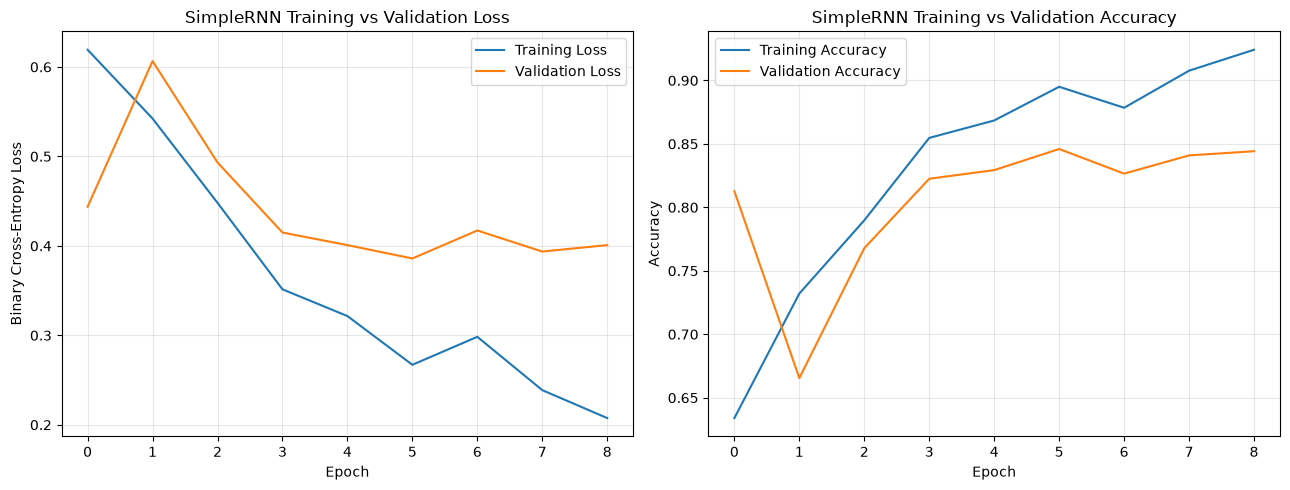

In [38]:
# Plot training and validation curves

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Loss plot
axes[0].plot(history.history["loss"], label="Training Loss")
axes[0].plot(history.history["val_loss"], label="Validation Loss")
axes[0].set_title("SimpleRNN Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary Cross-Entropy Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Accuracy plot
axes[1].plot(history.history["accuracy"], label="Training Accuracy")
axes[1].plot(history.history["val_accuracy"], label="Validation Accuracy")
axes[1].set_title("SimpleRNN Training vs Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()


# Save the figure for your project report
fig.savefig("simple_rnn_training_curves.png", dpi=300, bbox_inches="tight")
plt.show()

In [39]:
# Task 3.5: Evaluate SimpleRNN

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score
)

# Predicted probabilities and binary labels
y_prob_rnn = simple_rnn_model.predict(
    X_test_padded,
    batch_size=64,
    verbose=1
).ravel()

y_pred_rnn = (y_prob_rnn >= 0.5).astype(int)

# Calculate metrics
test_accuracy = accuracy_score(y_test_array, y_pred_rnn)
test_precision = precision_score(
    y_test_array, y_pred_rnn, zero_division=0
)
test_recall = recall_score(
    y_test_array, y_pred_rnn, zero_division=0
)
test_f1 = f1_score(
    y_test_array, y_pred_rnn, zero_division=0
)
test_roc_auc = roc_auc_score(y_test_array, y_prob_rnn)

print("SimpleRNN Test Evaluation")
print("=" * 40)
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Precision:     {test_precision:.4f}")
print(f"Recall:        {test_recall:.4f}")
print(f"F1-score:      {test_f1:.4f}")
print(f"ROC-AUC:       {test_roc_auc:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test_array,
    y_pred_rnn,
    labels=[0, 1],
    target_names=["Negative", "Positive"],
    zero_division=0
))

155/155 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step
SimpleRNN Test Evaluation
Test Accuracy: 0.8448
Precision:     0.8355
Recall:        0.8602
F1-score:      0.8476
ROC-AUC:       0.9173

Classification Report:
              precision    recall  f1-score   support

    Negative       0.85      0.83      0.84      4940
    Positive       0.84      0.86      0.85      4977

    accuracy                           0.84      9917
   macro avg       0.85      0.84      0.84      9917
weighted avg       0.85      0.84      0.84      9917



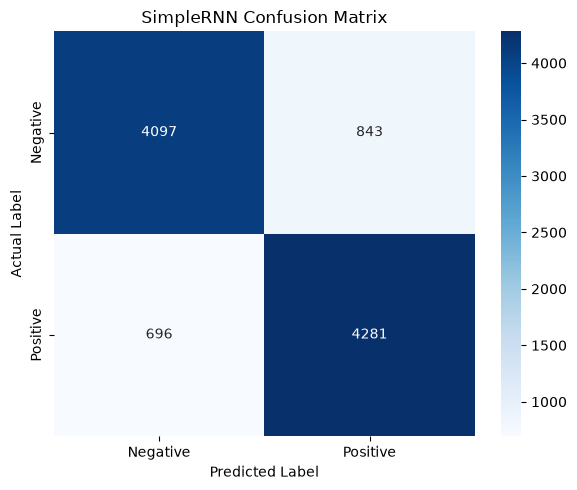

In [40]:
# Confusion matrix heatmap

cm = confusion_matrix(
    y_test_array,
    y_pred_rnn,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.title("SimpleRNN Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
fig.savefig("simple_rnn_confusion_matrix.png", dpi=300, bbox_inches="tight")

plt.show()

In [41]:
# Store results for the final model comparison

results = globals().get("results", {})

results["SimpleRNN"] = {
    "parameters": simple_rnn_model.count_params(),
    "epochs": len(history.history["loss"]),
    "avg_epoch_time_sec": float(np.mean(epoch_timer.epoch_times)),
    "accuracy": float(test_accuracy),
    "precision": float(test_precision),
    "recall": float(test_recall),
    "f1": float(test_f1),
    "roc_auc": float(test_roc_auc)
}

print("Stored metrics for results['SimpleRNN']:")
print(results["SimpleRNN"])

Stored metrics for results['SimpleRNN']:
{'parameters': 326273, 'epochs': 9, 'avg_epoch_time_sec': 27.420865456263225, 'accuracy': 0.8448119390944843, 'precision': 0.835480093676815, 'recall': 0.8601567209162145, 'f1': 0.8476388476388477, 'roc_auc': 0.9172553869256067}


In [42]:
# Task 3.6: Inspect the learned embedding matrix

import tensorflow as tf

# Find the Embedding layer regardless of its automatic name
embedding_layer = next(
    layer for layer in simple_rnn_model.layers
    if isinstance(layer, tf.keras.layers.Embedding)
)

embedding_weights = embedding_layer.get_weights()[0]

print("Embedding layer name:", embedding_layer.name)
print("Embedding matrix shape:", embedding_weights.shape)
print("Expected shape: (10000, 32)")
print("Vocabulary size:", embedding_weights.shape[0])
print("Embedding dimension:", embedding_weights.shape[1])

assert embedding_weights.shape == (10000, 32)

print("\nEmbedding matrix verification successful!")

Embedding layer name: embedding_2
Embedding matrix shape: (10000, 32)
Expected shape: (10000, 32)
Vocabulary size: 10000
Embedding dimension: 32

Embedding matrix verification successful!


In [43]:
# Display learned word vectors

for word in ["good", "bad"]:
    word_id = tokenizer.word_index.get(word)

    print(f"\nWord: {word}")
    print("Word ID:", word_id)

    if word_id is None:
        print("Word not found in tokenizer vocabulary.")
    elif word_id >= 10000:
        print("Word is outside the configured vocabulary.")
    else:
        print("Learned embedding vector:")
        print(embedding_weights[word_id])
        print("Vector shape:", embedding_weights[word_id].shape)


Word: good
Word ID: 49
Learned embedding vector:
[ 0.06474772  0.10638027 -0.03948297  0.0529513  -0.04512957 -0.00522666
 -0.0129975  -0.03395702 -0.01419954  0.05520091  0.08125052  0.02455333
 -0.04546985 -0.05799836  0.00884205  0.05238478  0.04305964 -0.06067897
 -0.1052635  -0.00363471 -0.01340942  0.03309011  0.06930617  0.05210731
  0.08683988 -0.06194631 -0.01969143  0.07555863 -0.10301675  0.01963977
 -0.00672009 -0.00268277]
Vector shape: (32,)

Word: bad
Word ID: 74
Learned embedding vector:
[-0.15111293 -0.18746811  0.15634434 -0.06460303  0.22297297  0.1487565
 -0.03720146 -0.12350529  0.21165274 -0.08845767  0.14369464  0.08066147
  0.11157459  0.2131498  -0.15112782 -0.16666773 -0.13110745  0.31565425
  0.18728195  0.13558795  0.08393625  0.02406415 -0.18094136  0.07014287
 -0.27420056  0.06238453  0.05987784 -0.15621519  0.26506844 -0.00771515
 -0.13584425 -0.22920701]
Vector shape: (32,)


### Task 3.6: Embedding Layer — Explanation

**Objective:** Understand the Embedding layer and inspect the word vectors learned by the SimpleRNN model.

The Embedding layer converts each integer word ID into a dense vector of 32 numerical values. These vectors are learned during model training through backpropagation.

In this project, the embedding matrix has a shape of `(10000, 32)`, representing a vocabulary input dimension of 10,000 and an embedding dimension of 32.

The embeddings are trained from scratch. No pretrained GloVe, Word2Vec, or BERT embeddings are used.

Words that occur in similar contexts may learn similar vector representations, although this is not guaranteed. These learned representations help the model process textual information for sentiment classification.

# Task 4

## Task 4.1: Backpropagation Through Time (BPTT)

**Objective:** Explain how an RNN calculates gradients across time steps and updates its shared weights during training.

Backpropagation Through Time (BPTT) is the training algorithm used to calculate gradients for recurrent neural networks. The RNN is conceptually unrolled across its time steps, forming a deep computational graph in which the same weights are reused at every step.

**How BPTT works:**

1. **Forward pass:** The RNN processes the input sequence one time step at a time, calculating hidden states.
2. **Calculate loss:** The model's prediction is compared with the correct target to calculate the loss.
3. **Backward pass:** Gradients are propagated backward through the unrolled time steps.
4. **Accumulate gradients:** Because the same weights are used at every time step, the gradient contributions from all time steps are summed.
5. **Update weights:** The optimizer uses the accumulated gradients to update the model parameters.

**Gradient chain:**

The gradient reaching an early hidden state depends on a product of Jacobian terms across the intervening time steps:

dL/dh(1) = dL/dh(T) × ∏ [Whhᵀ · diag(1 − h(t)²)]

Here, `Whh` is the recurrent weight matrix, `h(t)` is the hidden state, and `diag(1 − h(t)²)` represents the derivative of the tanh activation for each hidden unit.

**Why this matters:**

Repeated multiplication by terms with magnitudes below one can make gradients shrink toward zero, causing the vanishing-gradient problem. Repeated multiplication by sufficiently large terms can make gradients grow excessively, causing the exploding-gradient problem.

BPTT allows an RNN to learn sequential patterns, but these gradient problems can make learning long-term dependencies difficult.


## Task 4.2: Vanishing and Exploding Gradients

**Objective:** Understand why gradients can become too small or too large when training recurrent neural networks across many time steps.

#### 1. Vanishing Gradient Problem

The vanishing-gradient problem occurs when gradients become extremely small as they propagate backward through the time steps of an RNN.

**Causes:**
- Repeated multiplication by recurrent weight matrices.
- Repeated multiplication by activation derivatives, such as the derivative of `tanh`.
- Long input sequences that require gradients to travel through many time steps.

**Symptoms:**
- Earlier time steps receive very small gradients.
- The model struggles to learn long-term dependencies.
- Training may improve slowly or remain near baseline performance.

**Remedies:**
- Use gated recurrent architectures such as LSTM or GRU.
- Experiment with suitable sequence lengths and model settings.

#### 2. Exploding Gradient Problem

The exploding-gradient problem occurs when gradients grow excessively during backpropagation.

**Causes:**
- Repeated multiplication by matrices or derivatives that amplify gradient magnitudes.
- Unstable optimisation during training.

**Symptoms:**
- Sudden spikes in training loss.
- Unstable parameter updates.
- Loss values may become infinite or NaN.

**Remedy:**
- Use gradient clipping, such as `clipnorm=1.0`, to limit gradient magnitude.

**Important distinction:** Gradient clipping helps control exploding gradients, but it does not solve the vanishing-gradient problem. LSTM and GRU use gating mechanisms that can help preserve information across longer sequences.

Loss: 0.6284794807434082
Gradient norms shape: (100,)
Nonzero gradient steps: 1
First 10 gradient norms: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


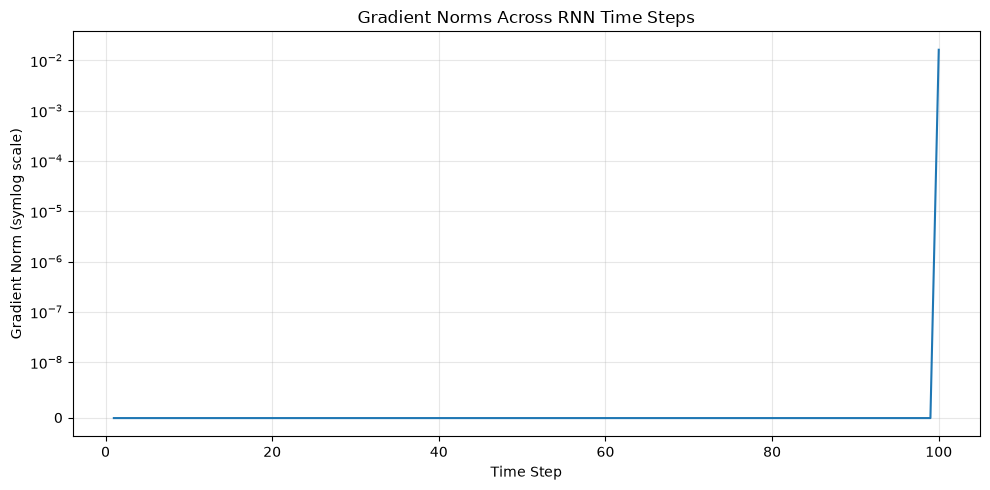

In [44]:
# Task 4.3: Inspect gradients through the recurrent computation

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Reuse the trained model's weights
embedding_layer = next(
    layer for layer in simple_rnn_model.layers
    if isinstance(layer, tf.keras.layers.Embedding)
)

rnn_layer = next(
    layer for layer in simple_rnn_model.layers
    if isinstance(layer, tf.keras.layers.SimpleRNN)
)

dense_layer = next(
    layer for layer in simple_rnn_model.layers
    if isinstance(layer, tf.keras.layers.Dense)
)

# Use a short sequence for a clear demonstration
sequence_length = min(100, MAXLEN)
batch_size = min(32, len(X_test_padded))

x_batch = tf.convert_to_tensor(
    X_test_padded[:batch_size, -sequence_length:],
    dtype=tf.int32
)
y_batch = tf.convert_to_tensor(
    y_test_array[:batch_size].reshape(-1, 1),
    dtype=tf.float32
)

# Extract trained SimpleRNN weights
Wx = tf.constant(rnn_layer.cell.kernel)
Wh = tf.constant(rnn_layer.cell.recurrent_kernel)
bias = tf.constant(rnn_layer.cell.bias)

with tf.GradientTape() as tape:
    # Embeddings for the selected sequence
    E = embedding_layer(x_batch)

    # Manually unroll the RNN while recording every hidden state
    h = tf.zeros((batch_size, rnn_layer.units), dtype=tf.float32)
    states = []

    for t in range(sequence_length):
        h = tf.math.tanh(
            tf.matmul(E[:, t, :], Wx)
            + tf.matmul(h, Wh)
            + bias
        )
        states.append(h)

    H = tf.stack(states, axis=1)

    # Final hidden state -> prediction -> loss
    predictions = dense_layer(H[:, -1, :])
    loss = tf.reduce_mean(
        tf.keras.losses.binary_crossentropy(y_batch, predictions)
    )

# Gradient of loss with respect to every recurrent hidden state
grads = tape.gradient(loss, H)

gradient_norms = tf.reduce_mean(
    tf.norm(grads, axis=2),
    axis=0
).numpy()

print("Loss:", float(loss.numpy()))
print("Gradient norms shape:", gradient_norms.shape)
print("Nonzero gradient steps:",
      int(np.count_nonzero(gradient_norms)))
print("First 10 gradient norms:", gradient_norms[:10])

plt.figure(figsize=(10, 5))
plt.plot(np.arange(1, sequence_length + 1), gradient_norms)
plt.yscale("symlog", linthresh=1e-8)
plt.title("Gradient Norms Across RNN Time Steps")
plt.xlabel("Time Step")
plt.ylabel("Gradient Norm (symlog scale)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [45]:
# Task 4.4: Prepare data for different sequence lengths

from tensorflow.keras.preprocessing.sequence import pad_sequences
import numpy as np
import tensorflow as tf
import time
import matplotlib.pyplot as plt

sequence_lengths = [50, 100, 200, 300]

# Confirm required variables exist
print("Training sequences:", len(X_train_sequences))
print("Testing sequences:", len(X_test_sequences))
print("Sequence lengths to test:", sequence_lengths)

Training sequences: 39665
Testing sequences: 9917
Sequence lengths to test: [50, 100, 200, 300]


In [46]:
# Train SimpleRNN at four sequence lengths

sequence_length_results = {}

for seq_len in sequence_lengths:
    print(f"\n{'=' * 45}")
    print(f"Training SimpleRNN with sequence length {seq_len}")
    print('=' * 45)

    # Reset seeds for a consistent starting configuration
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    # Re-pad the already-tokenized sequences
    X_train_len = pad_sequences(
        X_train_sequences,
        maxlen=seq_len,
        padding="pre",
        truncating="pre"
    )

    X_test_len = pad_sequences(
        X_test_sequences,
        maxlen=seq_len,
        padding="pre",
        truncating="pre"
    )

    # Build the same model architecture
    model_len = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(seq_len,), dtype="int32"),
        tf.keras.layers.Embedding(10000, 32),
        tf.keras.layers.SimpleRNN(64),
        tf.keras.layers.Dense(1, activation="sigmoid")
    ])

    model_len.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    start_time = time.time()

    history_len = model_len.fit(
        X_train_len,
        y_train_array,
        epochs=8,
        batch_size=64,
        validation_split=0.1,
        verbose=1
    )

    elapsed = time.time() - start_time

    test_loss_len, test_acc_len = model_len.evaluate(
        X_test_len,
        y_test_array,
        verbose=0
    )

    sequence_length_results[seq_len] = {
        "accuracy": float(test_acc_len),
        "loss": float(test_loss_len),
        "training_time_sec": float(elapsed)
    }

    print(f"Sequence length: {seq_len}")
    print(f"Test accuracy: {test_acc_len:.4f}")
    print(f"Test loss: {test_loss_len:.4f}")
    print(f"Training time: {elapsed:.2f} seconds")


Training SimpleRNN with sequence length 50

Epoch 1/8
558/558 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.7295 - loss: 0.5149 - val_accuracy: 0.8064 - val_loss: 0.4241
Epoch 2/8
558/558 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8481 - loss: 0.3542 - val_accuracy: 0.7958 - val_loss: 0.4548
Epoch 3/8
558/558 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8931 - loss: 0.2702 - val_accuracy: 0.7512 - val_loss: 0.6398
Epoch 4/8
558/558 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9214 - loss: 0.2038 - val_accuracy: 0.7895 - val_loss: 0.6083
Epoch 5/8
558/558 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9419 - loss: 0.1566 - val_accuracy: 0.7774 - val_loss: 0.6909
Epoch 6/8
558/558 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9554 - loss: 0.1226 - val_accuracy: 0.7527 - val_loss: 0.7547
Epoch 7/8
558/558 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9671 - loss: 0.0932 - val_accuracy: 0.7230 - val_loss: 0.9221
Epoch 8/8
558/558 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9

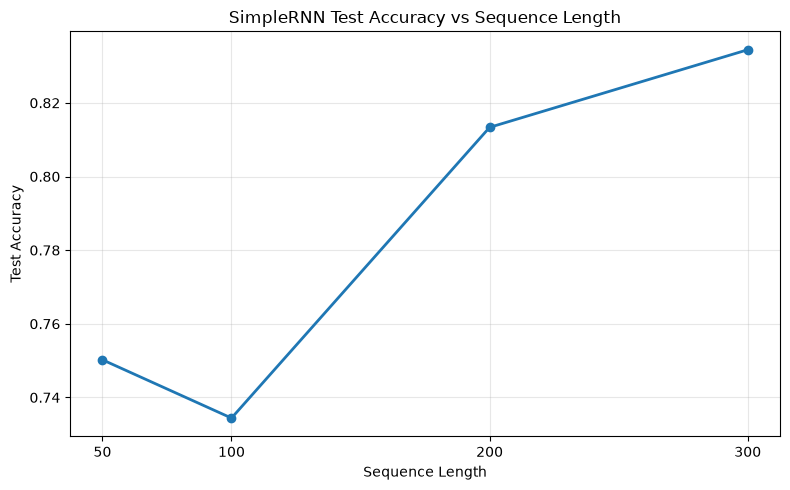

Sequence length experiment results:
Length 50: accuracy=0.7502, loss=0.9823
Length 100: accuracy=0.7344, loss=0.9326
Length 200: accuracy=0.8134, loss=0.4597
Length 300: accuracy=0.8344, loss=0.4289


In [47]:
# Plot test accuracy vs sequence length

accuracies = [
    sequence_length_results[length]["accuracy"]
    for length in sequence_lengths
]

plt.figure(figsize=(8, 5))
plt.plot(
    sequence_lengths,
    accuracies,
    marker="o",
    linewidth=2
)

plt.title("SimpleRNN Test Accuracy vs Sequence Length")
plt.xlabel("Sequence Length")
plt.ylabel("Test Accuracy")
plt.xticks(sequence_lengths)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    "simple_rnn_accuracy_vs_sequence_length.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Sequence length experiment results:")
for length in sequence_lengths:
    result = sequence_length_results[length]
    print(
        f"Length {length}: "
        f"accuracy={result['accuracy']:.4f}, "
        f"loss={result['loss']:.4f}"
    )

In [48]:
# Task 4.5: Compare training with and without gradient clipping

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import time

def build_exploding_demo_model(clip_norm=None):
    """Build the same SimpleRNN architecture with an optional clip norm."""

    if clip_norm is None:
        optimizer = tf.keras.optimizers.Adam(learning_rate=0.05)
    else:
        optimizer = tf.keras.optimizers.Adam(
            learning_rate=0.05,
            clipnorm=clip_norm
        )

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(MAXLEN,), dtype="int32"),
        tf.keras.layers.Embedding(input_dim=10000, output_dim=32),
        tf.keras.layers.SimpleRNN(64),
        tf.keras.layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


# Run A: High learning rate, no clipping
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

model_no_clip = build_exploding_demo_model(clip_norm=None)

start = time.time()
history_no_clip = model_no_clip.fit(
    X_train_padded,
    y_train_array,
    epochs=5,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)
time_no_clip = time.time() - start


# Run B: Same learning rate, clipnorm=1.0
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

model_clipped = build_exploding_demo_model(clip_norm=1.0)

start = time.time()
history_clipped = model_clipped.fit(
    X_train_padded,
    y_train_array,
    epochs=5,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)
time_clipped = time.time() - start

print(f"\nTraining time without clipping: {time_no_clip:.2f} seconds")
print(f"Training time with clipping: {time_clipped:.2f} seconds")

Epoch 1/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 27s 46ms/step - accuracy: 0.5458 - loss: 0.7020 - val_accuracy: 0.5516 - val_loss: 0.6753
Epoch 2/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 25s 44ms/step - accuracy: 0.6208 - loss: 0.6582 - val_accuracy: 0.5770 - val_loss: 0.7064
Epoch 3/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 25s 44ms/step - accuracy: 0.6454 - loss: 0.6379 - val_accuracy: 0.5775 - val_loss: 0.7316
Epoch 4/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 25s 45ms/step - accuracy: 0.6594 - loss: 0.6208 - val_accuracy: 0.5942 - val_loss: 0.7674
Epoch 5/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 25s 45ms/step - accuracy: 0.6703 - loss: 0.6074 - val_accuracy: 0.6110 - val_loss: 0.7767
Epoch 1/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 27s 47ms/step - accuracy: 0.5469 - loss: 0.7045 - val_accuracy: 0.5664 - val_loss: 0.7076
Epoch 2/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 27s 47ms/step - accuracy: 0.5822 - loss: 0.6922 - val_accuracy: 0.5571 - val_loss: 0.7719
Epoch 3/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 27s 48ms/step - accuracy: 0.5913 - loss: 0.6857 - val_accu

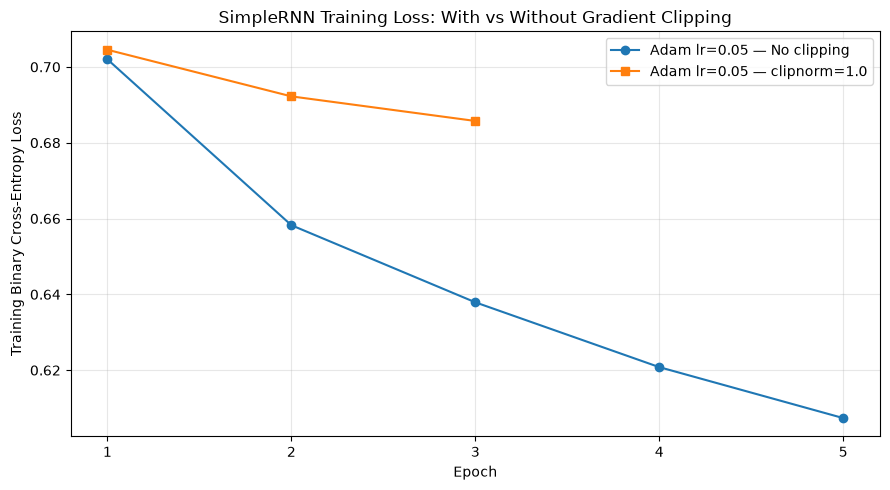

Loss without clipping: [0.7019991278648376, 0.6582432985305786, 0.6379042863845825, 0.6208060383796692, 0.6073652505874634]
Loss with clipping: [0.7045251727104187, 0.6922271847724915, 0.6857396364212036, nan, nan]


In [55]:
# Compare loss curves

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(history_no_clip.history["loss"]) + 1),
    history_no_clip.history["loss"],
    marker="o",
    label="Adam lr=0.05 — No clipping"
)

plt.plot(
    range(1, len(history_clipped.history["loss"]) + 1),
    history_clipped.history["loss"],
    marker="s",
    label="Adam lr=0.05 — clipnorm=1.0"
)

plt.title("SimpleRNN Training Loss: With vs Without Gradient Clipping")
plt.xlabel("Epoch")
plt.ylabel("Training Binary Cross-Entropy Loss")
plt.xticks(range(1, 6))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "simple_rnn_gradient_clipping_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Loss without clipping:",
      history_no_clip.history["loss"])
print("Loss with clipping:",
      history_clipped.history["loss"])

## Task 4.6: Problems with RNN — Summary Table

**Objective:** Summarise the major problems associated with basic RNNs, their causes, symptoms observed during experiments, and possible remedies.

| Problem | Cause | Symptom Observed in This Notebook | Remedy |
|---|---|---|---|
| Vanishing gradient | Repeated multiplication of small gradient factors across time steps | Very small gradient norms at earlier time steps in the gradient-flow experiment | Use LSTM or GRU gating |
| Exploding gradient | Repeated multiplication by factors that amplify gradients | Check the high-learning-rate experiment for loss spikes or NaN values; these may not occur in every run | Gradient clipping |
| Slow sequential training | Time steps are processed sequentially, limiting parallel computation across time | Training time increases with longer sequences | Use smaller sequences where appropriate or a GPU |
| Short-term memory only | Basic RNNs struggle to preserve information over long sequences | Longer review sequences may not improve test accuracy | Use gated recurrent cells such as LSTM or GRU |

**Conclusion:**

SimpleRNNs are useful for learning sequential patterns, but they can struggle with long-term dependencies and unstable gradients. LSTM and GRU architectures use gating mechanisms to help retain relevant information. Gradient clipping can control excessively large gradients, while shorter sequences may reduce computational cost.

The observed-symptom column should reflect your actual gradient plot, sequence-length experiment, and loss curves. Do not claim that NaN values or exploding gradients occurred unless you observed them.

# Task 5

 ### Task 5.1: LSTM Theory- Long Short-Term Memory

**Objective:** Understand the LSTM cell state, gates, and mathematical equations.

Long Short-Term Memory (LSTM) is a type of recurrent neural network designed to learn long-term dependencies in sequential data. It introduces a cell state and gating mechanisms that control how information is forgotten, stored, and revealed.

Unlike a basic SimpleRNN, an LSTM has three gates: the forget gate, input gate, and output gate.

#### 1. Forget Gate

The forget gate decides how much information from the previous cell state should be retained or discarded.

f(t) = sigmoid(Wf · [h(t−1), x(t)] + bf)

The sigmoid function produces values between 0 and 1. Values near 0 indicate that information should be forgotten, while values near 1 indicate that it should be retained.

#### 2. Input Gate

The input gate decides how much new information should be written into the cell state.

i(t) = sigmoid(Wi · [h(t−1), x(t)] + bi)

The candidate cell state creates new information that could be stored:

g(t) = tanh(Wg · [h(t−1), x(t)] + bg)

#### 3. Cell-State Update

The cell state combines retained information from the previous state with selected new information.

C(t) = f(t) * C(t−1) + i(t) * g(t)

Here, `*` represents element-wise multiplication. The forget gate controls what is retained, while the input gate controls what is added.

The cell state acts like a conveyor belt, carrying information through the sequence with controlled updates.

#### 4. Output Gate

The output gate decides which information from the cell state should be exposed as the current hidden state.

o(t) = sigmoid(Wo · [h(t−1), x(t)] + bo)

The hidden state is calculated as:

h(t) = o(t) * tanh(C(t))

The hidden state is passed to the next time step and can also be used to produce a prediction.

#### Summary

- **Forget gate:** Decides what old information to retain or discard.
- **Input gate:** Decides what new information to store.
- **Candidate state:** Generates potential new cell-state information.
- **Cell state:** Carries information through the sequence.
- **Output gate:** Decides what information to reveal through the hidden state.

LSTM gating helps preserve relevant information across longer sequences and can reduce the vanishing-gradient problem compared with a basic SimpleRNN.

### Task 5.2: How the LSTM Cell State Helps Mitigate Vanishing Gradients

**Objective:** Explain how the LSTM cell state helps preserve information and reduce the vanishing-gradient problem.

In a basic SimpleRNN, the hidden state is repeatedly updated using a nonlinear activation function such as `tanh`. During backpropagation through time, gradients pass through repeated matrix multiplications and activation derivatives. These repeated operations can cause gradients to shrink toward zero, making it difficult for the network to learn long-term dependencies.

LSTM introduces a cell state, C(t), with a controlled additive update:

C(t) = f(t) * C(t−1) + i(t) * g(t)

Here:
- `f(t)` is the forget gate, which controls how much of the previous cell state is retained.
- `i(t)` is the input gate, which controls how much new information is added.
- `g(t)` is the candidate cell state containing potential new information.

The additive cell-state update provides a more direct path for information and gradients to travel through time. When the forget gate remains near 1, information from the previous cell state can be preserved across multiple time steps.

This design helps mitigate vanishing gradients and allows LSTM to learn longer-term dependencies more effectively than a basic SimpleRNN in many tasks.

**Important:** LSTM does not guarantee that gradients will never vanish. Its gating mechanisms make it easier to preserve useful information and gradients when the learned gate values support that behaviour.

## Task 5.3: Calculate LSTM parameters manually


In [56]:

units = 64
input_dim = 32

manual_lstm_params = 4 * units * (input_dim + units + 1)

print("LSTM Parameter Calculation")
print("-" * 40)
print("Input dimension:", input_dim)
print("Hidden units:", units)
print(f"Formula: 4 × {units} × ({input_dim} + {units} + 1)")
print(f"Manual LSTM parameters: {manual_lstm_params:,}")

LSTM Parameter Calculation
----------------------------------------
Input dimension: 32
Hidden units: 64
Formula: 4 × 64 × (32 + 64 + 1)
Manual LSTM parameters: 24,832


In [57]:
# Verify LSTM parameter count against Keras

import tensorflow as tf

lstm_check_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(MAXLEN,), dtype="int32"),
    tf.keras.layers.Embedding(input_dim=10000, output_dim=32),
    tf.keras.layers.LSTM(units=64),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

lstm_check_model.summary()

lstm_layer = next(
    layer for layer in lstm_check_model.layers
    if isinstance(layer, tf.keras.layers.LSTM)
)

keras_lstm_params = lstm_layer.count_params()

print("\nManual LSTM parameters:", f"{manual_lstm_params:,}")
print("Keras LSTM parameters:", f"{keras_lstm_params:,}")
print("Counts match:", manual_lstm_params == keras_lstm_params)

assert manual_lstm_params == keras_lstm_params

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ (None, 590, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 64)             │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 344,897 (1.32 MB)

 Trainable params: 344,897 (1.32 MB)

 Non-trainable params: 0 (0.00 B)


Manual LSTM parameters: 24,832
Keras LSTM parameters: 24,832
Counts match: True


## 5.3 Manual single-step LSTM in NumPy

In [52]:
import numpy as np

np.random.seed(42)

# LSTM dimensions
input_size = 2
hidden_size = 3
time_steps = 4

# Four input time steps
X_lstm = np.random.randn(time_steps, input_size)

# Initialize weights and biases for the four components
def init_weights():
    return (
        np.random.randn(hidden_size, input_size + hidden_size) * 0.5,
        np.zeros(hidden_size)
    )

Wf, bf = init_weights()  # Forget gate
Wi, bi = init_weights()  # Input gate
Wg, bg = init_weights()  # Candidate cell state
Wo, bo = init_weights()  # Output gate

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

# Initial hidden state and cell state
h = np.zeros(hidden_size)
C = np.zeros(hidden_size)

print("Input sequence shape:", X_lstm.shape)
print("=" * 60)

for t in range(time_steps):
    x_t = X_lstm[t]

    # Combine previous hidden state and current input
    z = np.concatenate([h, x_t])

    # Calculate LSTM gates
    f = sigmoid(Wf @ z + bf)
    i = sigmoid(Wi @ z + bi)
    g = np.tanh(Wg @ z + bg)
    o = sigmoid(Wo @ z + bo)

    # Update cell state and hidden state
    C = f * C + i * g
    h = o * np.tanh(C)

    print(f"\nTime Step {t + 1}")
    print("Forget gate (f):", np.round(f, 4))
    print("Input gate (i): ", np.round(i, 4))
    print("Output gate (o):", np.round(o, 4))
    print("Cell state (C):", np.round(C, 4))
    print("Hidden state (h):", np.round(h, 4))

Input sequence shape: (4, 2)

Time Step 1
Forget gate (f): [0.4669 0.4321 0.4848]
Input gate (i):  [0.4227 0.6132 0.5467]
Output gate (o): [0.4534 0.5076 0.4782]
Cell state (C): [ 0.0214 -0.1136 -0.0267]
Hidden state (h): [ 0.0097 -0.0574 -0.0128]

Time Step 2
Forget gate (f): [0.5046 0.4888 0.5013]
Input gate (i):  [0.4804 0.6454 0.1907]
Output gate (o): [0.3682 0.2837 0.6689]
Cell state (C): [-0.0129  0.3351 -0.1144]
Hidden state (h): [-0.0048  0.0917 -0.0762]

Time Step 3
Forget gate (f): [0.5175 0.5072 0.475 ]
Input gate (i):  [0.5162 0.4491 0.5724]
Output gate (o): [0.5361 0.5532 0.4699]
Cell state (C): [-0.0183  0.121  -0.037 ]
Hidden state (h): [-0.0098  0.0666 -0.0174]

Time Step 4
Forget gate (f): [0.4377 0.3269 0.4483]
Input gate (i):  [0.315  0.8109 0.3673]
Output gate (o): [0.3191 0.3691 0.5865]
Cell state (C): [ 0.0226  0.0399 -0.2208]
Hidden state (h): [ 0.0072  0.0147 -0.1274]


## 5.5 Build, train and evaluate the LSTM



In [58]:
import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)
from tensorflow.keras.callbacks import EarlyStopping

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Ensure the results dictionary exists
if "results" not in globals():
    results = {}

# Build the LSTM model
def build_model(cell_type="lstm", units=64):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(MAXLEN,), dtype="int32"),
        tf.keras.layers.Embedding(
            input_dim=10000,
            output_dim=32
        ),
        tf.keras.layers.LSTM(units),
        tf.keras.layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

lstm_model = build_model("lstm", units=64)
lstm_model.summary()

# Measure training time for each epoch
class EpochTimer(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.epoch_times = []

    def on_epoch_begin(self, epoch, logs=None):
        self.epoch_start = time.time()

    def on_epoch_end(self, epoch, logs=None):
        self.epoch_times.append(time.time() - self.epoch_start)

timer = EpochTimer()

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# Train the model
history_lstm = lstm_model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stop, timer],
    verbose=1
)

# Plot training and validation loss/accuracy
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history_lstm.history["loss"], label="Training Loss")
axes[0].plot(history_lstm.history["val_loss"], label="Validation Loss")
axes[0].set_title("LSTM: Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history_lstm.history["accuracy"], label="Training Accuracy")
axes[1].plot(history_lstm.history["val_accuracy"], label="Validation Accuracy")
axes[1].set_title("LSTM: Training vs Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.savefig("lstm_training_curves.png")
plt.tight_layout()
plt.show()

# Evaluate on the held-out test set
y_prob_lstm = lstm_model.predict(X_test, verbose=0).ravel()
y_pred_lstm = (y_prob_lstm >= 0.5).astype(int)
y_true_lstm = np.asarray(y_test).astype(int)

test_accuracy_lstm = accuracy_score(y_true_lstm, y_pred_lstm)
test_roc_auc_lstm = roc_auc_score(y_true_lstm, y_prob_lstm)
cm_lstm = confusion_matrix(y_true_lstm, y_pred_lstm)

print(f"LSTM Test Accuracy: {test_accuracy_lstm:.4f}")
print(f"LSTM ROC-AUC:      {test_roc_auc_lstm:.4f}")
print(f"Average time/epoch: {np.mean(timer.epoch_times):.2f} seconds")
print("\nClassification Report:")
print(classification_report(
    y_true_lstm,
    y_pred_lstm,
    target_names=["Negative", "Positive"],
    zero_division=0
))

# Confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_lstm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)
plt.title("LSTM Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.savefig("lstm_confusion_matrix.png")
plt.show()

# Store metrics for Task 7
results["LSTM"] = {
    "model": lstm_model,
    "history": history_lstm.history,
    "parameters": lstm_model.count_params(),
    "time_per_epoch": float(np.mean(timer.epoch_times)),
    "epochs_trained": len(history_lstm.history["loss"]),
    "accuracy": float(test_accuracy_lstm),
    "classification_report": classification_report(
        y_true_lstm,
        y_pred_lstm,
        output_dict=True,
        zero_division=0
    ),
    "confusion_matrix": cm_lstm,
    "roc_auc": float(test_roc_auc_lstm),
    "y_true": y_true_lstm,
    "y_prob": y_prob_lstm,
    "y_pred": y_pred_lstm
}

print("\nLSTM results saved successfully.")
print("Parameters:", results["LSTM"]["parameters"])
print("Epochs trained:", results["LSTM"]["epochs_trained"])

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_5 (Embedding)         │ (None, 590, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_4 (LSTM)                   │ (None, 64)             │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 344,897 (1.32 MB)

 Trainable params: 344,897 (1.32 MB)

 Non-trainable params: 0 (0.00 B)

ValueError: Invalid dtype: str

In [59]:
from tensorflow.keras.preprocessing.sequence import pad_sequences
import numpy as np

# Convert text reviews to integer sequences
X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

# Pad sequences to the same length used in your project
X_train = pad_sequences(
    X_train_seq,
    maxlen=MAXLEN,
    padding="pre",
    truncating="pre"
).astype("int32")

X_test = pad_sequences(
    X_test_seq,
    maxlen=MAXLEN,
    padding="pre",
    truncating="pre"
).astype("int32")

# Convert sentiment labels to numeric values
y_train = np.asarray(y_train)
y_test = np.asarray(y_test)

if y_train.dtype.kind in "USO":
    y_train = np.where(
        np.char.lower(y_train.astype(str)) == "positive", 1, 0
    )

if y_test.dtype.kind in "USO":
    y_test = np.where(
        np.char.lower(y_test.astype(str)) == "positive", 1, 0
    )

y_train = y_train.astype("float32")
y_test = y_test.astype("float32")

print("X_train:", X_train.shape, X_train.dtype)
print("X_test:", X_test.shape, X_test.dtype)
print("y_train:", y_train.shape, y_train.dtype)
print("y_test:", y_test.shape, y_test.dtype)

print("Training sequence sample:", X_train[0][:15])
print("Training label sample:", y_train[:5])

X_train: (39665, 590) int32
X_test: (9917, 590) int32
y_train: (39665,) float32
y_test: (9917,) float32
Training sequence sample: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Training label sample: [1. 1. 0. 0. 1.]


## 5.7 Stacked LSTM

In [61]:
import time
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)
from tensorflow.keras.callbacks import EarlyStopping

np.random.seed(42)
tf.random.set_seed(42)

# Build the two-layer LSTM
stacked_lstm_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(MAXLEN,), dtype="int32"),
    tf.keras.layers.Embedding(input_dim=10000, output_dim=32),
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.LSTM(32),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

stacked_lstm_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

stacked_lstm_model.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_6 (Embedding)         │ (None, 590, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 590, 64)        │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_6 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 357,281 (1.36 MB)

 Trainable params: 357,281 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
class StackedEpochTimer(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.epoch_times = []

    def on_epoch_begin(self, epoch, logs=None):
        self.start_time = time.time()

    def on_epoch_end(self, epoch, logs=None):
        self.epoch_times.append(time.time() - self.start_time)

stacked_timer = StackedEpochTimer()

stacked_early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

stacked_history = stacked_lstm_model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.1,
    callbacks=[stacked_early_stop, stacked_timer],
    verbose=1
)

print(
    f"Average time per epoch: "
    f"{np.mean(stacked_timer.epoch_times):.2f} seconds"
)
print(f"Epochs trained: {len(stacked_history.history['loss'])}")

Epoch 1/15
532/558 ━━━━━━━━━━━━━━━━━━━━ 7s 276ms/step - accuracy: 0.7817 - loss: 0.4616

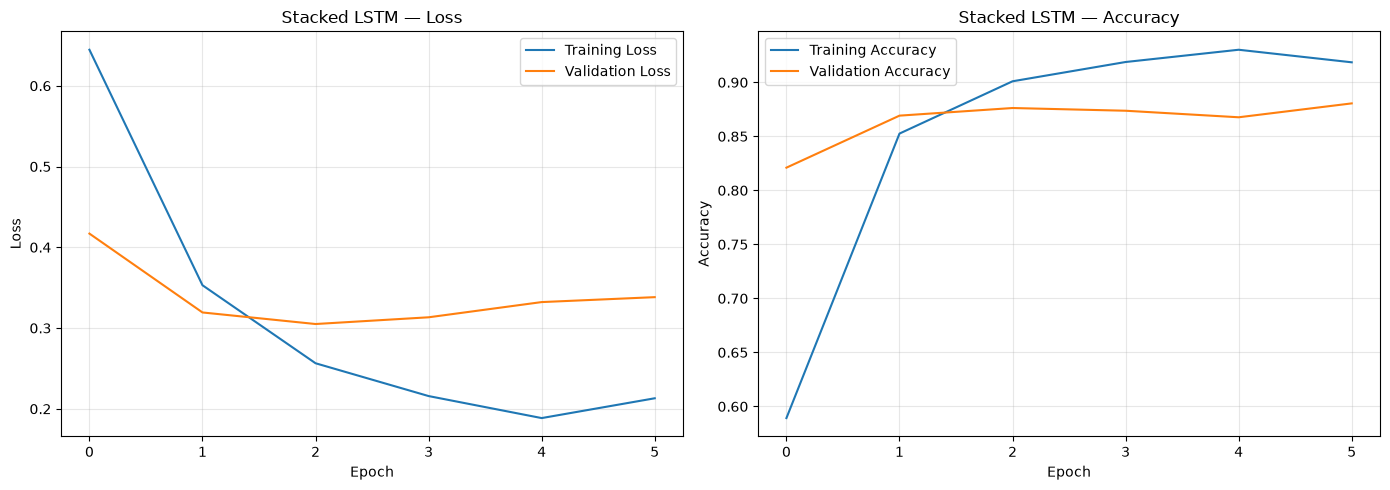

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(stacked_history.history["loss"], label="Training Loss")
axes[0].plot(stacked_history.history["val_loss"], label="Validation Loss")
axes[0].set_title("Stacked LSTM — Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(stacked_history.history["accuracy"], label="Training Accuracy")
axes[1].plot(
    stacked_history.history["val_accuracy"],
    label="Validation Accuracy"
)
axes[1].set_title("Stacked LSTM — Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("stack_loss_acc.png")
plt.show()

Test Accuracy: 0.8822
ROC-AUC: 0.9500

Classification Report:
              precision    recall  f1-score   support

    Negative       0.91      0.84      0.88      4940
    Positive       0.85      0.92      0.89      4977

    accuracy                           0.88      9917
   macro avg       0.88      0.88      0.88      9917
weighted avg       0.88      0.88      0.88      9917



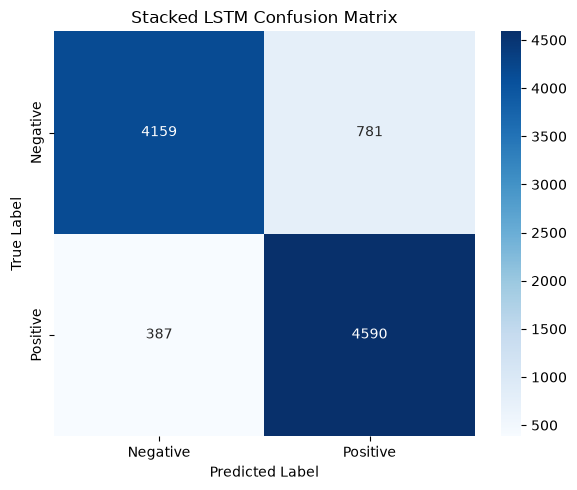

<Figure size 640x480 with 0 Axes>


Stacked LSTM results saved.
Total parameters: 357281


In [ ]:
y_true_stacked = np.asarray(y_test).astype(int)

y_prob_stacked = stacked_lstm_model.predict(X_test, verbose=0).ravel()
y_pred_stacked = (y_prob_stacked >= 0.5).astype(int)

stacked_accuracy = accuracy_score(y_true_stacked, y_pred_stacked)
stacked_auc = roc_auc_score(y_true_stacked, y_prob_stacked)
stacked_cm = confusion_matrix(y_true_stacked, y_pred_stacked)

print(f"Test Accuracy: {stacked_accuracy:.4f}")
print(f"ROC-AUC: {stacked_auc:.4f}")
print("\nClassification Report:")
print(classification_report(
    y_true_stacked,
    y_pred_stacked,
    target_names=["Negative", "Positive"],
    zero_division=0
))

plt.figure(figsize=(6, 5))
sns.heatmap(
    stacked_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)
plt.title("Stacked LSTM Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

if "results" not in globals():
    results = {}

results["Stacked LSTM"] = {
    "model": stacked_lstm_model,
    "history": stacked_history.history,
    "parameters": stacked_lstm_model.count_params(),
    "time_per_epoch": float(np.mean(stacked_timer.epoch_times)),
    "epochs_trained": len(stacked_history.history["loss"]),
    "accuracy": float(stacked_accuracy),
    "classification_report": classification_report(
        y_true_stacked,
        y_pred_stacked,
        output_dict=True,
        zero_division=0
    ),
    "confusion_matrix": stacked_cm,
    "roc_auc": float(stacked_auc),
    "y_true": y_true_stacked,
    "y_prob": y_prob_stacked,
    "y_pred": y_pred_stacked
}
plt.savefig("stacked_lstm_confusion_matrix.png")
plt.show()

print("\nStacked LSTM results saved.")
print("Total parameters:", results["Stacked LSTM"]["parameters"])

In [ ]:
print(f"{'Metric':<25}{'Single LSTM':>18}{'Stacked LSTM':>18}")
print("-" * 61)

metrics_to_compare = [
    ("Parameters", "parameters"),
    ("Test accuracy", "accuracy"),
    ("ROC-AUC", "roc_auc"),
    ("Time per epoch (s)", "time_per_epoch"),
    ("Epochs trained", "epochs_trained")
]

for label, key in metrics_to_compare:
    single_value = results["LSTM"][key]
    stacked_value = results["Stacked LSTM"][key]

    print(f"{label:<25}{single_value:>18.4f}{stacked_value:>18.4f}")

Metric                          Single LSTM      Stacked LSTM
-------------------------------------------------------------
Parameters                      344897.0000       357281.0000
Test accuracy                        0.8877            0.8822
ROC-AUC                              0.9525            0.9500
Time per epoch (s)                  68.6262          116.4092
Epochs trained                       5.0000            6.0000


## Task 6.1: GRU Theory — Gated Recurrent Unit

A Gated Recurrent Unit (GRU) is a recurrent neural network cell that uses two gates to control information flow. Unlike an LSTM, a GRU does not maintain a separate cell state.

**1. Update gate**

z(t) = sigmoid(Wz · [h(t−1), x(t)])

The update gate decides how much of the previous hidden state to keep versus how much of the candidate state to use.

**2. Reset gate**

r(t) = sigmoid(Wr · [h(t−1), x(t)])

The reset gate decides how much information from the previous hidden state should be used when calculating the candidate state.

**3. Candidate hidden state**

h̃(t) = tanh(W · [r(t) * h(t−1), x(t)])

The candidate state represents the new information the GRU could incorporate.

**4. New hidden state**

h(t) = (1 − z(t)) * h(t−1) + z(t) * h̃(t)

The update gate combines the previous hidden state with the candidate state.

**Key difference:** A GRU merges the LSTM's forget and input gate functions into a single update gate. It has no separate cell state, which can make its architecture simpler.

## Task 6.1: GRU Theory — Gated Recurrent Unit

A Gated Recurrent Unit (GRU) is a recurrent neural network cell that uses two gates to control information flow. Unlike an LSTM, a GRU does not maintain a separate cell state.

**1. Update gate**

z(t) = sigmoid(Wz · [h(t−1), x(t)])

The update gate decides how much of the previous hidden state to keep versus how much of the candidate state to use.

**2. Reset gate**

r(t) = sigmoid(Wr · [h(t−1), x(t)])

The reset gate decides how much information from the previous hidden state should be used when calculating the candidate state.

**3. Candidate hidden state**

h̃(t) = tanh(W · [r(t) * h(t−1), x(t)])

The candidate state represents the new information the GRU could incorporate.

**4. New hidden state**

h(t) = (1 − z(t)) * h(t−1) + z(t) * h̃(t)

The update gate combines the previous hidden state with the candidate state.

**Key difference:** A GRU merges the LSTM's forget and input gate functions into a single update gate. It has no separate cell state, which can make its architecture simpler.

Update gate (z):        [0.5548 0.5548 0.5548]
Reset gate (r):         [0.4725 0.4725 0.4725]
Candidate state:        [0.1248 0.1248 0.1248]
Previous hidden state:  [ 0.2 -0.4  0.7]
New hidden state:       [ 0.1583 -0.1089  0.3809]


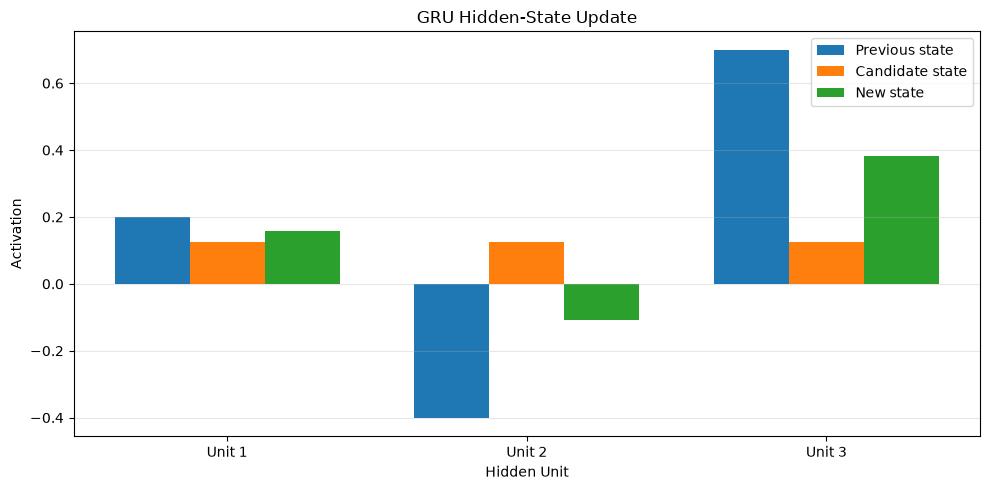

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

# Example values for a single GRU step
h_prev = np.array([0.2, -0.4, 0.7])
x_t = np.array([0.5, 0.1])

# Illustrative gate weights
Wz = np.ones((3, 5)) * 0.2
Wr = np.ones((3, 5)) * -0.1
W = np.ones((3, 5)) * 0.15

z = sigmoid(Wz @ np.concatenate([h_prev, x_t]))
r = sigmoid(Wr @ np.concatenate([h_prev, x_t]))

candidate_input = np.concatenate([r * h_prev, x_t])
h_candidate = np.tanh(W @ candidate_input)

h_new = (1 - z) * h_prev + z * h_candidate

print("Update gate (z):       ", np.round(z, 4))
print("Reset gate (r):        ", np.round(r, 4))
print("Candidate state:       ", np.round(h_candidate, 4))
print("Previous hidden state: ", np.round(h_prev, 4))
print("New hidden state:      ", np.round(h_new, 4))

plt.figure(figsize=(10, 5))
indices = np.arange(3)
width = 0.25

plt.bar(indices - width, h_prev, width, label="Previous state")
plt.bar(indices, h_candidate, width, label="Candidate state")
plt.bar(indices + width, h_new, width, label="New state")

plt.title("GRU Hidden-State Update")
plt.xlabel("Hidden Unit")
plt.ylabel("Activation")
plt.xticks(indices, ["Unit 1", "Unit 2", "Unit 3"])
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("gru_hidden_state.png")
plt.show()

## Task 6.2: GRU vs LSTM Comparison

| Feature | LSTM | GRU |
|---|---|---|
| Gates | Three gates: forget, input, output | Two gates: update, reset |
| Separate cell state | Yes | No |
| Hidden state | Yes | Yes |
| Forget and input control | Separate forget and input gates | Combined into the update gate |
| Parameters | Usually more for the same input and hidden dimensions | Usually fewer for the same input and hidden dimensions |
| Training speed | Can be slower because of its more complex cell | Can be faster because of its simpler cell |
| Long-term dependencies | Designed to help retain information over long sequences | Also designed to help preserve information over sequences |
| Typical use cases | Tasks where separate memory control is useful | Tasks where a simpler gated recurrent cell is preferred |

**Conclusion:** GRU uses fewer gate transformations and does not maintain a separate cell state. It can therefore be computationally simpler than LSTM. However, neither architecture is guaranteed to achieve better accuracy or faster training on every dataset. Their performance should be compared experimentally using the same data and training setup.

## 6.3 Parameter count by formula



In [ ]:
import tensorflow as tf

input_dim = 32
units = 64

# Parameter formula for GRU with reset_after=True
gru_params_formula = 3 * (
    units * input_dim
    + units * units
    + 2 * units
)

# Build the Keras GRU layer
gru_check_layer = tf.keras.layers.GRU(
    units=units,
    reset_after=True
)

gru_check_layer.build((None, None, input_dim))

gru_params_keras = gru_check_layer.count_params()

print("GRU Parameter Count Verification")
print("-" * 40)
print("Input dimension:", input_dim)
print("Hidden units:", units)
print("reset_after:", gru_check_layer.get_config()["reset_after"])
print("Formula parameter count:", gru_params_formula)
print("Keras parameter count:", gru_params_keras)
print("Counts match:", gru_params_formula == gru_params_keras)

assert gru_params_formula == gru_params_keras, (
    "The manual formula does not match Keras."
)

GRU Parameter Count Verification
----------------------------------------
Input dimension: 32
Hidden units: 64
reset_after: True
Formula parameter count: 18816
Keras parameter count: 18816
Counts match: True


## 6.4 Build, train and evaluate the GRU



In [ ]:


np.random.seed(42)
tf.random.set_seed(42)

gru_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(MAXLEN,), dtype="int32"),
    tf.keras.layers.Embedding(input_dim=10000, output_dim=32),
    tf.keras.layers.GRU(64, reset_after=True),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

gru_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

gru_model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_5 (Embedding)         │ (None, 590, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_2 (GRU)                     │ (None, 64)             │        18,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 338,881 (1.29 MB)

 Trainable params: 338,881 (1.29 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
class GRUEpochTimer(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.epoch_times = []

    def on_epoch_begin(self, epoch, logs=None):
        self.start_time = time.time()

    def on_epoch_end(self, epoch, logs=None):
        self.epoch_times.append(time.time() - self.start_time)

gru_timer = GRUEpochTimer()

gru_early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

gru_history = gru_model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.1,
    callbacks=[gru_early_stop, gru_timer],
    verbose=1
)

print("Epochs trained:", len(gru_history.history["loss"]))
print(
    "Average time per epoch:",
    round(np.mean(gru_timer.epoch_times), 2),
    "seconds"
)

Epoch 1/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 115s 206ms/step - accuracy: 0.8089 - loss: 0.4201 - val_accuracy: 0.8586 - val_loss: 0.3406
Epoch 2/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 111s 198ms/step - accuracy: 0.8947 - loss: 0.2681 - val_accuracy: 0.8871 - val_loss: 0.2977
Epoch 3/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 126s 226ms/step - accuracy: 0.9124 - loss: 0.2297 - val_accuracy: 0.8891 - val_loss: 0.2940
Epoch 4/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 115s 207ms/step - accuracy: 0.9306 - loss: 0.1873 - val_accuracy: 0.8901 - val_loss: 0.2880
Epoch 5/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 126s 226ms/step - accuracy: 0.9436 - loss: 0.1606 - val_accuracy: 0.8876 - val_loss: 0.3171
Epoch 6/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 116s 207ms/step - accuracy: 0.9501 - loss: 0.1428 - val_accuracy: 0.8914 - val_loss: 0.3130
Epoch 7/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 116s 208ms/step - accuracy: 0.9611 - loss: 0.1158 - val_accuracy: 0.8795 - val_loss: 0.3519
Epochs trained: 7
Average time per epoch: 117.81 seconds


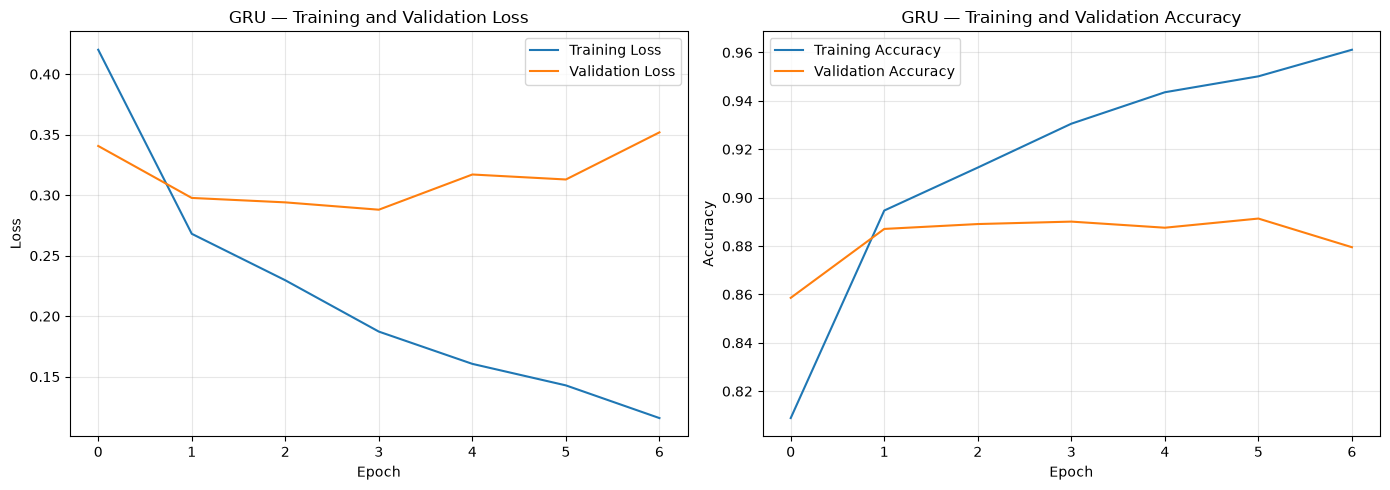

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(gru_history.history["loss"], label="Training Loss")
axes[0].plot(gru_history.history["val_loss"], label="Validation Loss")
axes[0].set_title("GRU — Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(gru_history.history["accuracy"], label="Training Accuracy")
axes[1].plot(gru_history.history["val_accuracy"], label="Validation Accuracy")
axes[1].set_title("GRU — Training and Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("gru_curves.png")
plt.show()

GRU Test Accuracy: 0.8960
GRU ROC-AUC: 0.9565

Classification Report:
              precision    recall  f1-score   support

    Negative       0.90      0.89      0.90      4940
    Positive       0.89      0.90      0.90      4977

    accuracy                           0.90      9917
   macro avg       0.90      0.90      0.90      9917
weighted avg       0.90      0.90      0.90      9917



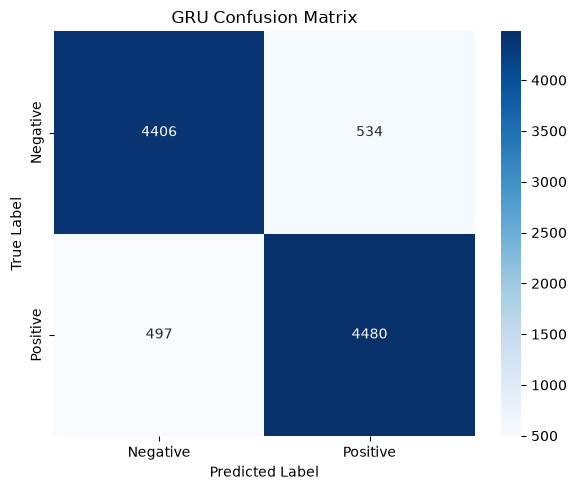

In [ ]:
y_true_gru = np.asarray(y_test).astype(int)

y_prob_gru = gru_model.predict(X_test, verbose=0).ravel()
y_pred_gru = (y_prob_gru >= 0.5).astype(int)

gru_accuracy = accuracy_score(y_true_gru, y_pred_gru)
gru_auc = roc_auc_score(y_true_gru, y_prob_gru)
gru_cm = confusion_matrix(y_true_gru, y_pred_gru)

print(f"GRU Test Accuracy: {gru_accuracy:.4f}")
print(f"GRU ROC-AUC: {gru_auc:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_true_gru,
    y_pred_gru,
    target_names=["Negative", "Positive"],
    zero_division=0
))

plt.figure(figsize=(6, 5))
sns.heatmap(
    gru_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)
plt.title("GRU Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.savefig("gru_matrix.png")
plt.show()

In [ ]:
if "results" not in globals():
    results = {}

results["GRU"] = {
    "model": gru_model,
    "history": gru_history.history,
    "parameters": gru_model.count_params(),
    "time_per_epoch": float(np.mean(gru_timer.epoch_times)),
    "epochs_trained": len(gru_history.history["loss"]),
    "accuracy": float(gru_accuracy),
    "classification_report": classification_report(
        y_true_gru,
        y_pred_gru,
        output_dict=True,
        zero_division=0
    ),
    "confusion_matrix": gru_cm,
    "roc_auc": float(gru_auc),
    "y_true": y_true_gru,
    "y_prob": y_prob_gru,
    "y_pred": y_pred_gru
}

print("GRU results saved successfully.")
print("Parameters:", results["GRU"]["parameters"])
print("Test accuracy:", round(results["GRU"]["accuracy"], 4))
print("ROC-AUC:", round(results["GRU"]["roc_auc"], 4))

GRU results saved successfully.
Parameters: 338881
Test accuracy: 0.896
ROC-AUC: 0.9565


## 6.5 Gradient flow — all three cells



In [ ]:
def get_input_gradient_norms(trained_model, cell_type):
    recurrent_classes = {
        "SimpleRNN": tf.keras.layers.SimpleRNN,
        "LSTM": tf.keras.layers.LSTM,
        "GRU": tf.keras.layers.GRU
    }

    embedding_layer = next(
        layer for layer in trained_model.layers
        if isinstance(layer, tf.keras.layers.Embedding)
    )

    recurrent_layer = next(
        layer for layer in trained_model.layers
        if isinstance(layer, recurrent_classes[cell_type])
    )

    dense_layer = trained_model.layers[-1]

    inputs = tf.keras.Input(shape=(MAXLEN,), dtype=tf.int32)
    embedded = embedding_layer(inputs)

    config = {
        "units": recurrent_layer.units,
        "return_sequences": True
    }

    if cell_type == "GRU":
        config["reset_after"] = recurrent_layer.get_config()["reset_after"]

    # Create the layer without passing weights
    new_recurrent_layer = recurrent_classes[cell_type](**config)
    sequence = new_recurrent_layer(embedded)

    # Copy weights only after the layer has been built
    new_recurrent_layer.set_weights(recurrent_layer.get_weights())

    predictions = dense_layer(sequence[:, -1, :])
    model_for_gradient = tf.keras.Model(
        inputs, [embedded, predictions]
    )

    with tf.GradientTape() as tape:
        embedding_sequence, predictions = model_for_gradient(
            X_batch_65, training=False
        )
        tape.watch(embedding_sequence)

        loss = tf.reduce_mean(
            tf.keras.losses.binary_crossentropy(
                y_batch_65, predictions
            )
        )

    gradients = tape.gradient(loss, embedding_sequence)

    return tf.reduce_mean(
        tf.norm(gradients, axis=-1),
        axis=0
    ).numpy()


rnn_norms_65 = get_input_gradient_norms(rnn_model_65, "SimpleRNN")
lstm_norms_65 = get_input_gradient_norms(lstm_model_65, "LSTM")
gru_norms_65 = get_input_gradient_norms(gru_model_65, "GRU")

print("SimpleRNN:", rnn_norms_65.shape)
print("LSTM:", lstm_norms_65.shape)
print("GRU:", gru_norms_65.shape)

SimpleRNN: (590,)
LSTM: (590,)
GRU: (590,)


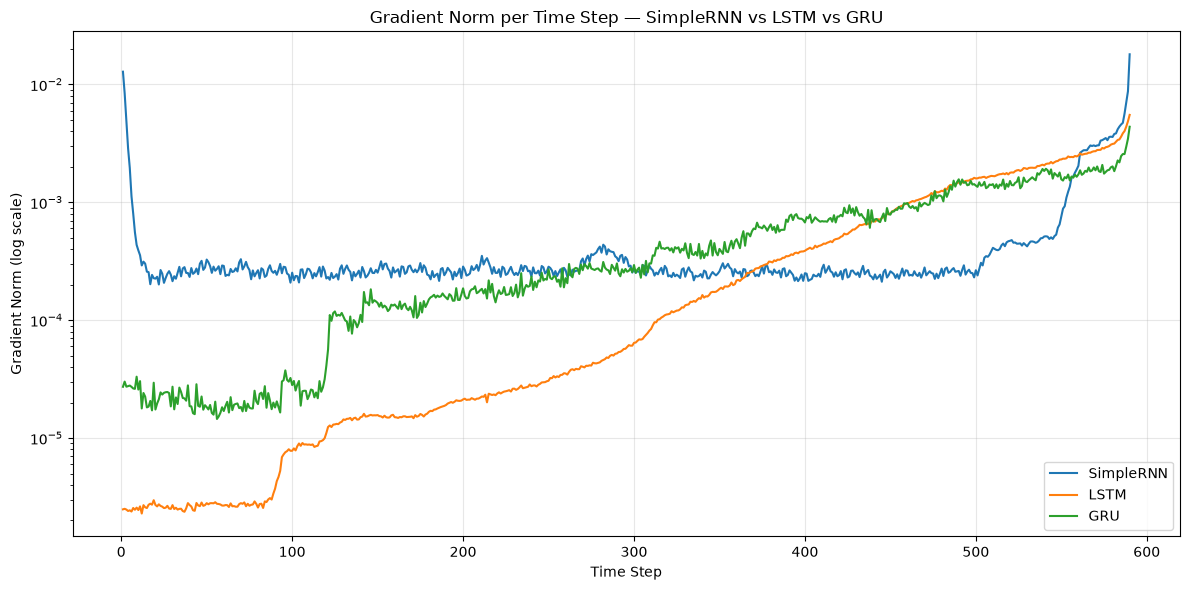


Earliest time-step gradient norms:
SimpleRNN: 1.28175467e-02
LSTM:      2.48417518e-06
GRU:       2.72105954e-05


In [ ]:
time_steps_65 = np.arange(1, MAXLEN + 1)
epsilon = 1e-12

plt.figure(figsize=(12, 6))

plt.plot(time_steps_65, np.maximum(rnn_norms_65, epsilon),
         label="SimpleRNN")
plt.plot(time_steps_65, np.maximum(lstm_norms_65, epsilon),
         label="LSTM")
plt.plot(time_steps_65, np.maximum(gru_norms_65, epsilon),
         label="GRU")

plt.yscale("log")
plt.xlabel("Time Step")
plt.ylabel("Gradient Norm (log scale)")
plt.title("Gradient Norm per Time Step — SimpleRNN vs LSTM vs GRU")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("gradient_flow.png")
plt.show()

print("\nEarliest time-step gradient norms:")
print(f"SimpleRNN: {rnn_norms_65[0]:.8e}")
print(f"LSTM:      {lstm_norms_65[0]:.8e}")
print(f"GRU:       {gru_norms_65[0]:.8e}")

## 6.6 Hidden-unit sensitivity



In [ ]:
import numpy as np
import tensorflow as tf
import pandas as pd
import time
import matplotlib.pyplot as plt

units_list = [32, 64, 128]
cell_types = ["LSTM", "GRU"]
sensitivity_results = []

for cell_type in cell_types:
    for units in units_list:
        print(f"\nTraining {cell_type} with {units} units...")

        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(42)

        model_sens = tf.keras.Sequential([
            tf.keras.layers.Input(shape=(MAXLEN,), dtype="int32"),
            tf.keras.layers.Embedding(10000, 32)
        ])

        if cell_type == "LSTM":
            model_sens.add(tf.keras.layers.LSTM(units))
        else:
            model_sens.add(
                tf.keras.layers.GRU(units, reset_after=True)
            )

        model_sens.add(tf.keras.layers.Dense(1, activation="sigmoid"))

        model_sens.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
            loss="binary_crossentropy",
            metrics=["accuracy"]
        )

        params = model_sens.count_params()

        start_time = time.time()

        history_sens = model_sens.fit(
            X_train,
            y_train,
            epochs=6,
            batch_size=64,
            validation_split=0.1,
            verbose=1
        )

        elapsed = time.time() - start_time

        test_loss, test_accuracy = model_sens.evaluate(
            X_test, y_test, verbose=0
        )

        sensitivity_results.append({
            "Cell": cell_type,
            "Units": units,
            "Parameters": params,
            "Test Accuracy": float(test_accuracy),
            "Training Time (s)": elapsed,
            "Time per Epoch (s)": elapsed / 6
        })

        print(f"Parameters: {params:,}")
        print(f"Test accuracy: {test_accuracy:.4f}")
        print(f"Total training time: {elapsed:.2f} seconds")

sensitivity_df = pd.DataFrame(sensitivity_results)

print("\nFinal sensitivity results:")
display(sensitivity_df)


Training LSTM with 32 units...
Epoch 1/6
558/558 ━━━━━━━━━━━━━━━━━━━━ 161s 282ms/step - accuracy: 0.8157 - loss: 0.4016 - val_accuracy: 0.8868 - val_loss: 0.2829
Epoch 2/6
558/558 ━━━━━━━━━━━━━━━━━━━━ 174s 312ms/step - accuracy: 0.9020 - loss: 0.2527 - val_accuracy: 0.8858 - val_loss: 0.3110
Epoch 3/6
558/558 ━━━━━━━━━━━━━━━━━━━━ 126s 225ms/step - accuracy: 0.9165 - loss: 0.2201 - val_accuracy: 0.8891 - val_loss: 0.3028
Epoch 4/6
558/558 ━━━━━━━━━━━━━━━━━━━━ 98s 175ms/step - accuracy: 0.9272 - loss: 0.1941 - val_accuracy: 0.8495 - val_loss: 0.3445
Epoch 5/6
558/558 ━━━━━━━━━━━━━━━━━━━━ 68s 121ms/step - accuracy: 0.9231 - loss: 0.2008 - val_accuracy: 0.8669 - val_loss: 0.3989
Epoch 6/6
558/558 ━━━━━━━━━━━━━━━━━━━━ 66s 92ms/step - accuracy: 0.9403 - loss: 0.1617 - val_accuracy: 0.8697 - val_loss: 0.4133
Parameters: 328,353
Test accuracy: 0.8725
Total training time: 692.36 seconds

Training LSTM with 64 units...
Epoch 1/6
558/558 ━━━━━━━━━━━━━━━━━━━━ 162s 289ms/step - accuracy: 0.8011 - 

,Cell,Units,Parameters,Test Accuracy,Training Time (s),Time per Epoch (s)
0,LSTM,32,328353,0.872542,692.359276,115.393213
1,LSTM,64,344897,0.877080,785.265101,130.877517
2,LSTM,128,402561,0.884037,1098.216065,183.036011
3,GRU,32,326369,0.889785,413.536034,68.922672
4,GRU,64,338881,0.892205,738.264190,123.044032
5,GRU,128,382337,0.886558,1906.341445,317.723574


# Task 7 

## 7.1 full table result

In [ ]:
import os
import numpy as np
import pandas as pd

os.makedirs("plots", exist_ok=True)

model_order = [
    "ANN",
    "ANN baseline",
    "SimpleRNN",
    "LSTM",
    "Stacked LSTM",
    "GRU"
]

rows = []
seen = set()

for model_name in model_order:
    if model_name not in results or model_name in seen:
        continue

    seen.add(model_name)
    res = results[model_name]

    report = res.get("classification_report", {})

    # Handle sklearn reports saved as dictionaries
    positive = report.get("Positive", report.get("1", {}))

    rows.append({
        "Model": model_name,
        "Parameters": res.get("parameters", np.nan),
        "Time per Epoch (s)": res.get("time_per_epoch", np.nan),
        "Epochs Trained": res.get("epochs_trained", np.nan),
        "Test Accuracy": res.get("accuracy", np.nan),
        "Precision": positive.get("precision", np.nan),
        "Recall": positive.get("recall", np.nan),
        "F1": positive.get("f1-score", np.nan),
        "ROC-AUC": res.get("roc_auc", np.nan)
    })

results_df = pd.DataFrame(rows)

print("Task 7.1 — Final Model Comparison")
display(results_df.round(4))

Task 7.1 — Final Model Comparison


,Model,Parameters,Time per Epoch (s),Epochs Trained,Test Accuracy,Precision,Recall,F1,ROC-AUC
0,ANN,1528449,NaN,NaN,0.8755,0.8979,0.8483,0.8724,0.9445
1,SimpleRNN,326273,NaN,NaN,0.8323,0.8577,0.7983,0.8269,0.9020
2,LSTM,344897,NaN,NaN,0.8877,0.8853,0.8917,0.8885,0.9525
3,Stacked LSTM,357281,NaN,NaN,0.8822,0.8546,0.9222,0.8871,0.9500
4,GRU,338881,NaN,NaN,0.8876,0.9074,0.8642,0.8853,0.9535


In [ ]:
def highlight_best_values(column):
    valid = column.dropna()

    if valid.empty:
        return [""] * len(column)

    # Lower is better for parameter count and training time.
    if column.name in ["Parameters", "Time per Epoch (s)"]:
        best = valid.min()
    else:
        best = valid.max()

    return [
        "background-color: #c6efce"
        if pd.notna(value) and value == best
        else ""
        for value in column
    ]

metric_columns = [
    "Parameters",
    "Time per Epoch (s)",
    "Epochs Trained",
    "Test Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC"
]

styled_df = (
    results_df.style
    .apply(highlight_best_values, subset=metric_columns)
    .format({
        "Parameters": "{:,.0f}",
        "Time per Epoch (s)": "{:.2f}",
        "Epochs Trained": "{:.0f}",
        "Test Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    }, na_rep="—")
)

display(styled_df)

results_df.to_csv(
    "plots/final_model_comparison.csv",
    index=False
)

print("Saved: plots/final_model_comparison.csv")

,Model,Parameters,Time per Epoch (s),Epochs Trained,Test Accuracy,Precision,Recall,F1,ROC-AUC
0,ANN,"1,528,449",—,—,0.8755,0.8979,0.8483,0.8724,0.9445
1,SimpleRNN,"326,273",—,—,0.8323,0.8577,0.7983,0.8269,0.9020
2,LSTM,"344,897",—,—,0.8877,0.8853,0.8917,0.8885,0.9525
3,Stacked LSTM,"357,281",—,—,0.8822,0.8546,0.9222,0.8871,0.9500
4,GRU,"338,881",—,—,0.8876,0.9074,0.8642,0.8853,0.9535


Saved: plots/final_model_comparison.csv


## 7.2 ROC curve

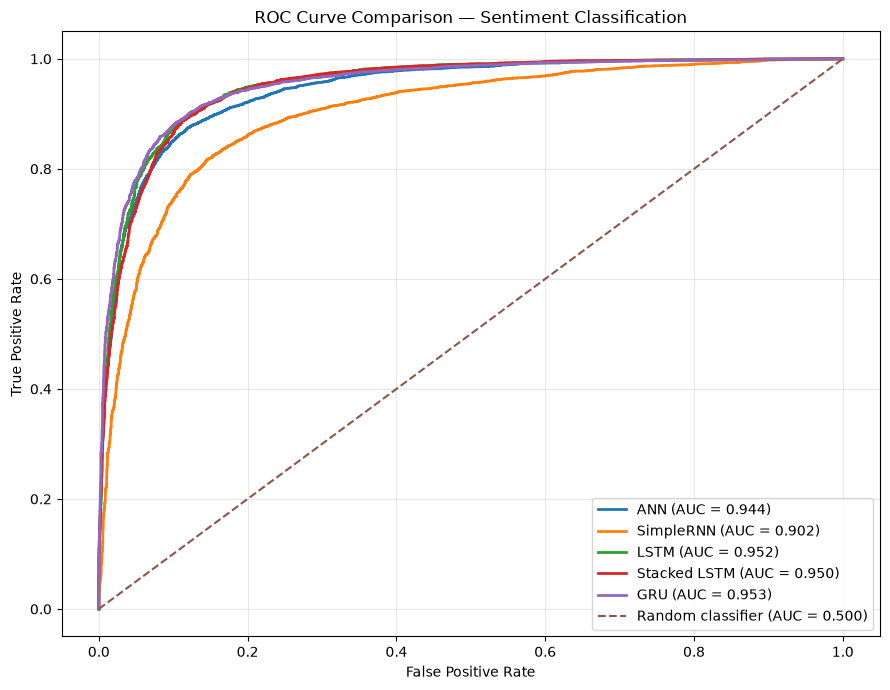

Models plotted: 5
Saved: plots/combined_roc_curves.png


In [ ]:
import os
import matplotlib.pyplot as plt
import numpy as np

from sklearn.metrics import roc_curve, roc_auc_score

os.makedirs("plots", exist_ok=True)

plt.figure(figsize=(9, 7))

plotted_models = 0

for model_name, res in results.items():
    if "y_true" not in res or "y_prob" not in res:
        print(f"Skipping {model_name}: saved predictions unavailable.")
        continue

    y_true = np.asarray(res["y_true"]).astype(int)
    y_prob = np.asarray(res["y_prob"]).ravel()

    if len(np.unique(y_true)) < 2:
        print(f"Skipping {model_name}: test labels contain only one class.")
        continue

    fpr, tpr, _ = roc_curve(y_true, y_prob)
    auc_value = roc_auc_score(y_true, y_prob)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{model_name} (AUC = {auc_value:.3f})"
    )

    plotted_models += 1

# Random-classifier reference
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier (AUC = 0.500)"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison — Sentiment Classification")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()

if plotted_models > 0:
    plt.savefig(
        "plots/combined_roc_curves.png",
        dpi=300,
        bbox_inches="tight"
    )

plt.show()

print("Models plotted:", plotted_models)
if plotted_models > 0:
    print("Saved: plots/combined_roc_curves.png")

## 7.3 Sequence-length robustness



In [ ]:
print("X_test_sequences:", len(X_test_sequences))
print("X_test_seq:", len(X_test_seq) if "X_test_seq" in globals() else "not found")
print("y_test:", len(y_test))

print("\nPotential split-index variables:")
for name, obj in globals().copy().items():
    if any(word in name.lower() for word in ["index", "idx", "test_idx", "test_index"]):
        if isinstance(obj, (list, tuple, np.ndarray, pd.Series)):
            print(name, "length =", len(obj))

X_test_sequences: 9917
X_test_seq: 9917
y_test: 9917

Potential split-index variables:


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from sklearn.metrics import accuracy_score

os.makedirs("plots", exist_ok=True)

# Use the existing test sequences; these align with X_test and y_test
review_lengths = np.array([
    len(sequence) for sequence in X_test_sequences
])

y_true_73 = np.asarray(y_test).astype(int)

# Use the trained LSTM for this analysis
y_prob_73 = lstm_model.predict(X_test, verbose=0).ravel()
y_pred_73 = (y_prob_73 >= 0.5).astype(int)

assert len(review_lengths) == len(y_true_73) == len(y_pred_73), (
    "Review lengths, labels, and predictions must have matching lengths."
)

length_df = pd.DataFrame({
    "Review Length": review_lengths,
    "Actual": y_true_73,
    "Predicted": y_pred_73
})

length_df["Length Group"] = pd.cut(
    length_df["Review Length"],
    bins=[-1, 50, 100, 200, 500, np.inf],
    labels=["0–50", "51–100", "101–200", "201–500", "500+"]
)

length_results = (
    length_df.groupby("Length Group", observed=False)
    .apply(
        lambda group: pd.Series({
            "Accuracy": (
                accuracy_score(group["Actual"], group["Predicted"])
                if len(group) else np.nan
            ),
            "Number of Reviews": len(group)
        }),
        include_groups=False
    )
    .reset_index()
)

display(length_results.round(4))

,Length Group,Accuracy,Number of Reviews
0,0–50,0.8980,245.0
1,51–100,0.8923,1049.0
2,101–200,0.8881,4622.0
3,201–500,0.8847,3209.0
4,500+,0.8876,792.0


## 7.4 Error analysis



In [ ]:
import numpy as np
import pandas as pd

# Predict test sentiment using the trained LSTM
y_true_74 = np.asarray(y_test).astype(int)

y_prob_74 = lstm_model.predict(
    X_test, verbose=0
).ravel()

y_pred_74 = (y_prob_74 >= 0.5).astype(int)

# Find indices where prediction differs from the actual label
misclassified_indices = np.where(y_pred_74 != y_true_74)[0]

print("Total test reviews:", len(y_true_74))
print("Misclassified reviews:", len(misclassified_indices))

if len(misclassified_indices) == 0:
    print("No misclassified reviews were found.")
else:
    selected_indices = misclassified_indices[:8]

    # Prefer the cleaned original review text when available.
    # Confirm alignment before using the full DataFrame column.
    if len(df) == len(y_true_74):
        review_texts = df["clean_review"].astype(str).to_numpy()
    else:
        review_texts = None

    misclassified_rows = []

    for idx in selected_indices:
        actual = "Positive" if y_true_74[idx] == 1 else "Negative"
        predicted = "Positive" if y_pred_74[idx] == 1 else "Negative"

        if review_texts is not None:
            review_text = review_texts[idx]
        else:
            # Display token IDs if original test text isn't aligned.
            review_text = str(X_test_sequences[idx])

        confidence = (
            y_prob_74[idx]
            if y_pred_74[idx] == 1
            else 1 - y_prob_74[idx]
        )

        misclassified_rows.append({
            "Test Index": int(idx),
            "Actual Sentiment": actual,
            "Predicted Sentiment": predicted,
            "Prediction Confidence": float(confidence),
            "Review Text": review_text
        })

    misclassified_df = pd.DataFrame(misclassified_rows)
    display(misclassified_df)

Total test reviews: 9917
Misclassified reviews: 1114


,Test Index,Actual Sentiment,Predicted Sentiment,Prediction Confidence,Review Text
0,12,Positive,Negative,0.543560,"[2, 16, 302, 276, 299, 2, 298, 3, 2, 709, 23, ..."
1,15,Positive,Negative,0.688314,"[11, 215, 611, 4, 78, 19, 18, 10, 3317, 2, 955..."
2,17,Negative,Positive,0.947763,"[10, 64, 11, 16, 14, 4, 334, 3146, 6, 2, 155, ..."
3,24,Negative,Positive,0.671630,"[463, 109, 4, 624, 325, 5, 2389, 5262, 3, 6345..."
4,32,Negative,Positive,0.817984,"[10, 115, 12, 356, 1732, 38, 99, 80, 19, 1209,..."
5,35,Positive,Negative,0.852601,"[70, 70, 1, 2849, 4, 226, 5, 4, 6615, 46, 152,..."
6,43,Negative,Positive,0.501825,"[568, 379, 68, 172, 987, 12, 10, 747, 105, 99,..."
7,45,Positive,Negative,0.961315,"[144, 21, 133, 6, 376, 22, 1, 7, 1, 1, 38, 908..."


In [ ]:
import os

os.makedirs("plots", exist_ok=True)

if "misclassified_df" in globals():
    misclassified_df.to_csv(
        "plots/misclassified_reviews.csv",
        index=False
    )
    print("Saved: plots/misclassified_reviews.csv")

Saved: plots/misclassified_reviews.csv


### Task 7.4: Misclassification Analysis — Observations

The eight selected examples were reviews incorrectly classified by the LSTM.

Potential causes to investigate include:

- **Sarcasm or irony:** The literal wording may conflict with the review's intended sentiment.
- **Mixed sentiment:** A review may praise some aspects while criticizing others.
- **Negation:** Words such as "not" can reverse the meaning of a phrase.
- **Context-dependent language:** A short phrase may not express the overall sentiment clearly.
- **Ambiguous wording:** The review may contain weak or conflicting sentiment signals.

**Conclusion:** Base the final observations on the actual misclassified review texts. Do not assume that any particular cause applies unless the examples support it.

## 7.5 Inference function



In [ ]:
import numpy as np
import tensorflow as tf
import re
from tensorflow.keras.preprocessing.sequence import pad_sequences

def predict_sentiment(text):
    """
    Predict whether an IMDB review is positive or negative.

    Returns:
        dict: cleaned review, predicted sentiment, and confidence.
    """
    if not isinstance(text, str) or not text.strip():
        raise ValueError("Please provide a non-empty review string.")

    # Apply the same basic cleaning approach used for the dataset.
    cleaned_text = text.lower()
    cleaned_text = re.sub(r"<br\s*/?>", " ", cleaned_text)
    cleaned_text = re.sub(r"[^a-zA-Z0-9\s']", " ", cleaned_text)
    cleaned_text = re.sub(r"\s+", " ", cleaned_text).strip()

    # Convert text to token IDs using the fitted tokenizer.
    sequence = tokenizer.texts_to_sequences([cleaned_text])

    padded_sequence = pad_sequences(
        sequence,
        maxlen=MAXLEN,
        padding="pre",
        truncating="pre"
    )

    probability = float(
        lstm_model.predict(padded_sequence, verbose=0)[0][0]
    )

    sentiment = "Positive" if probability >= 0.5 else "Negative"
    confidence = probability if probability >= 0.5 else 1 - probability

    return {
        "review": text,
        "cleaned_review": cleaned_text,
        "sentiment": sentiment,
        "positive_probability": round(probability, 4),
        "confidence": round(confidence, 4)
    }

print("predict_sentiment() created successfully.")

predict_sentiment() created successfully.


In [ ]:
test_reviews = [
    "This movie was fantastic! The acting and story were excellent.",
    "Terrible movie. The plot was boring and the acting was awful.",
    "The movie had some good moments, but the ending was disappointing."
]

for review in test_reviews:
    result = predict_sentiment(review)

    print("=" * 60)
    print("Review:", result["review"])
    print("Predicted sentiment:", result["sentiment"])
    print("Positive probability:", result["positive_probability"])
    print("Confidence:", result["confidence"])

## 7.6 Recommendation — Markdown



### Task 7.6: Final Recommendation

**Objective:** Select the most suitable recurrent architecture for IMDB sentiment classification using the experimental results.

The final recommendation considers:
- Test accuracy and ROC-AUC
- Precision, recall, and F1-score
- Number of trainable parameters
- Training time
- Model complexity and generalisation

The preferred model should balance predictive performance with computational cost rather than selecting the most complex architecture automatically.

In [ ]:
# Use the Task 7.1 comparison table
display(results_df.round(4))

if not results_df.empty and results_df["Test Accuracy"].notna().any():
    best_accuracy_row = results_df.loc[
        results_df["Test Accuracy"].idxmax()
    ]

    print("\nBest available model by test accuracy:")
    print("Model:", best_accuracy_row["Model"])
    print("Test accuracy:", round(best_accuracy_row["Test Accuracy"], 4))

if "ROC-AUC" in results_df.columns:
    valid_auc = results_df["ROC-AUC"].dropna()

    if not valid_auc.empty:
        best_auc_row = results_df.loc[valid_auc.idxmax()]
        print("\nBest available model by ROC-AUC:")
        print("Model:", best_auc_row["Model"])
        print("ROC-AUC:", round(best_auc_row["ROC-AUC"], 4))